In [123]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
import numpy as np
import pandas as pd
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/puneetbajajiitm/serpentguard-m2-splits/classes.csv
/kaggle/input/datasets/puneetbajajiitm/serpentguard-m2-splits/excluded.csv
/kaggle/input/datasets/puneetbajajiitm/serpentguard-m2-splits/split_report.json
/kaggle/input/datasets/puneetbajajiitm/serpentguard-m2-splits/splits.csv


# SerpentGuard AI — Milestone 2: Dataset EDA

**Group 5 · IIT Madras DS and AI Lab · 2026 T3**
Team: Jayesh Bansal (lead) · Vikas · Puneet Bajaj · Manas Rastogi
Date: 29 October 2026

Step-by-step exploratory analysis of `puneetbajajiitm/serpentguard-m2-splits`.
Dataset: 181,231 photos of 208 Indian snake species, split by photographer.

In [124]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
from pathlib import Path
warnings.filterwarnings("ignore")

In [125]:
# Colour conventions used throughout
WHO_COLORS  = {"1": "#e74c3c", "2": "#e67e22", "not_listed": "#2ecc71"}
WHO_LABELS  = {"1": "WHO Cat 1 (Critical)", "2": "WHO Cat 2 (Important)", "not_listed": "Not listed"}
SPLIT_COLORS = {
    "train": "#3498db", "val": "#9b59b6",
    "test": "#e74c3c", "test_extra": "#f39c12", "unknown_pool": "#95a5a6"
}
FMT = mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})

## Loading the Data

In [126]:
# Detect environment: inside Kaggle (/kaggle/input exists) or local
KAGGLE_INPUT = Path("/kaggle/input/serpentguard-m2-splits")
if KAGGLE_INPUT.exists():
    base = KAGGLE_INPUT
    print("Running inside Kaggle:", base)
else:
    base = Path(kagglehub.dataset_download("puneetbajajiitm/serpentguard-m2-splits"))
    print("Running locally:", base)

Running locally: /kaggle/input/datasets/puneetbajajiitm/serpentguard-m2-splits


In [127]:
df = pd.read_csv(base / "splits.csv")
print(f"splits.csv  — {len(df):,} rows, {len(df.columns)} columns")
df.head(3)

splits.csv  — 181,503 rows, 31 columns


,file,source,source_record_id,obs_id,photo_id,photo_position,species,genus,taxon_id,record_taxon,...,height,bytes,sha1,split,family,who_category,tier,m1_core27,cc_licensed,path
0,images/fowlea_piscator/inaturalist_55129.jpg,inaturalist,31985,31985,55129,0,Fowlea piscator,Fowlea,966799,Fowlea piscator,...,352,39508,4642f11acab7d860ad3bc0a36eb851e284cc3bf3,test_extra,Colubridae,not_listed,tier1,True,False,test_extra/fowlea_piscator/inaturalist_55129.jpg
1,images/fowlea_piscator/inaturalist_61193.jpg,inaturalist,36366,36366,61193,0,Fowlea piscator,Fowlea,966799,Fowlea piscator,...,333,26769,63665b95dbeae1891a9b0803162a0186a4fc7a72,train,Colubridae,not_listed,tier1,True,False,train/fowlea_piscator/inaturalist_61193.jpg
2,images/fowlea_piscator/inaturalist_152267.jpg,inaturalist,105808,105808,152267,0,Fowlea piscator,Fowlea,966799,Fowlea piscator,...,357,198137,a5f19499133164d76a6e473196d41cc12c6c614e,val,Colubridae,not_listed,tier1,True,True,val/fowlea_piscator/inaturalist_152267.jpg


In [128]:
classes  = pd.read_csv(base / "classes.csv")
excluded = pd.read_csv(base / "excluded.csv")
print(f"classes.csv  — {len(classes):,} rows")
print(f"excluded.csv — {len(excluded):,} rows")

classes.csv  — 208 rows
excluded.csv — 994 rows


In [129]:
# Parse date columns and extract year/month
df["observed_on"] = pd.to_datetime(df["observed_on"], errors="coerce")
df["created_at"]  = pd.to_datetime(df["created_at"],  errors="coerce")
df["year"]  = df["observed_on"].dt.year
df["month"] = df["observed_on"].dt.month
print("Date columns parsed. Year range:", int(df["year"].min()), "–", int(df["year"].max()))

Date columns parsed. Year range: 1968 – 2026


In [130]:
# Quick summary
print(f"Species:      {df['species'].nunique():,}")
print(f"Observers:    {df['observer_id'].nunique():,}")
print(f"Observations: {df['obs_id'].nunique():,}")
print(f"Genera:       {df['genus'].nunique():,}")
print(f"Families:     {df['family'].nunique():,}")
print(f"Columns:      {list(df.columns)}")

Species:      289
Observers:    25,070
Observations: 95,877
Genera:       77
Families:     14
Columns:      ['file', 'source', 'source_record_id', 'obs_id', 'photo_id', 'photo_position', 'species', 'genus', 'taxon_id', 'record_taxon', 'observer_id', 'observed_on', 'created_at', 'in_india', 'latitude', 'longitude', 'obscured', 'license', 'attribution', 'url', 'width', 'height', 'bytes', 'sha1', 'split', 'family', 'who_category', 'tier', 'm1_core27', 'cc_licensed', 'path', 'year', 'month']


---
## 1. How the Dataset Was Built

Numbers from the M2 project report (29 Oct 2026).

In [131]:
# Cleaning stages from the M2 report
pipeline = pd.DataFrame({
    "Stage": [
        "Raw download (iNaturalist)",
        "Remove exact duplicates (SHA-1)",
        "Remove conflicting-species duplicates",
        "Remove too small  (<5 KB or <100 px)",
        "Clean subtotal",
        "Remove pHash near-duplicates",
        "Final dataset",
    ],
    "Photos": [182497, 181569, 181539, 181503, 181503, 181231, 181231],
    "Removed": [0, 928, 30, 36, 0, 272, 0],
})
pipeline

,Stage,Photos,Removed
0,Raw download (iNaturalist),182497,0
1,Remove exact duplicates (SHA-1),181569,928
2,Remove conflicting-species duplicates,181539,30
3,Remove too small (<5 KB or <100 px),181503,36
4,Clean subtotal,181503,0
5,Remove pHash near-duplicates,181231,272
6,Final dataset,181231,0


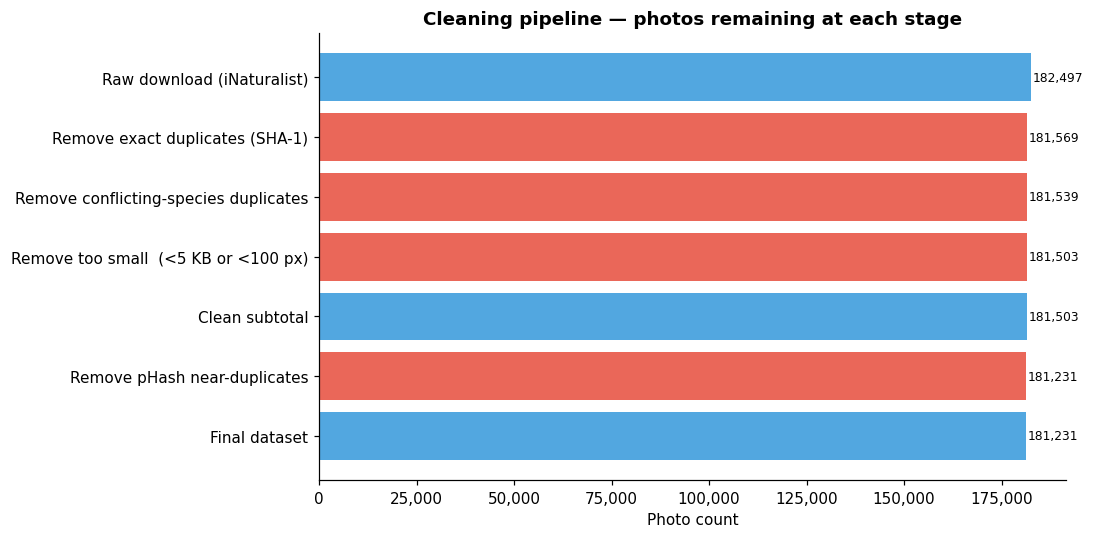

In [132]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#3498db" if r == 0 else "#e74c3c" for r in pipeline["Removed"]]
bars = ax.barh(pipeline["Stage"], pipeline["Photos"], color=colors, alpha=0.85)
for bar, row in zip(bars, pipeline.itertuples()):
    ax.text(bar.get_width() + 400, bar.get_y() + bar.get_height()/2,
            f"{row.Photos:,}", va="center", fontsize=8)
ax.set_xlabel("Photo count")
ax.set_title("Cleaning pipeline — photos remaining at each stage", fontweight="bold")
ax.xaxis.set_major_formatter(FMT)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [133]:
# Sources evaluated for this milestone
sources_tbl = pd.DataFrame([
    ("iNaturalist (India, research-grade)",  289, "181,503", "Used — primary source"),
    ("India Biodiversity Portal via GBIF",   180, "~1,800",  "HTTP 403 on scripted download"),
    ("SnakeCLEF 2021 Kaggle mirror",          -1, "~2,904",  "Deferred — 66 GB stops Kaggle kernels"),
    ("SnakeCLEF 2023 Kaggle mirror",         146, "4,989",   "Skipped — all iNaturalist copies"),
    ("Scraped Kaggle sets (India etc.)",      -1, "unknown", "Skipped — unclear copyright, no labels"),
    ("Manna et al. 2026 OSF folder",          -1, "793",     "Skipped — no species labels"),
    ("Open Images V7, class Snake",           -1, "~309 boxes", "Planned for M3 segmentation head"),
], columns=["Source", "Species", "Photos", "Decision"])
sources_tbl

,Source,Species,Photos,Decision
0,"iNaturalist (India, research-grade)",289,"181,503",Used — primary source
1,India Biodiversity Portal via GBIF,180,"~1,800",HTTP 403 on scripted download
2,SnakeCLEF 2021 Kaggle mirror,-1,"~2,904",Deferred — 66 GB stops Kaggle kernels
3,SnakeCLEF 2023 Kaggle mirror,146,"4,989",Skipped — all iNaturalist copies
4,Scraped Kaggle sets (India etc.),-1,unknown,"Skipped — unclear copyright, no labels"
5,Manna et al. 2026 OSF folder,-1,793,Skipped — no species labels
6,"Open Images V7, class Snake",-1,~309 boxes,Planned for M3 segmentation head


The iNaturalist data dominates. SnakeCLEF 2023 was fully skipped because every image is already in iNaturalist — adding it would silently duplicate photos across splits.

---
## 2. Dataset Overview

In [134]:
# Column types and null rates
info = pd.DataFrame({
    "dtype":   df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
})
info

,dtype,non_null,pct_missing
file,object,181503,0.00
source,object,181503,0.00
source_record_id,int64,181503,0.00
obs_id,int64,181503,0.00
photo_id,int64,181503,0.00
photo_position,int64,181503,0.00
species,object,181503,0.00
genus,object,181503,0.00
taxon_id,int64,181503,0.00
record_taxon,object,181503,0.00


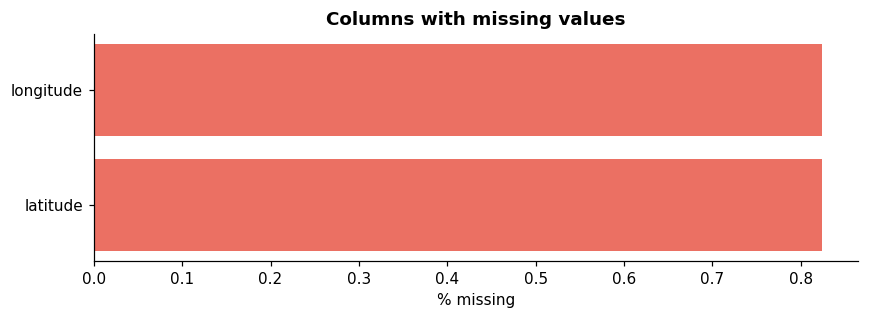

In [135]:
# Visualise missing values (only columns that have any)
missing = (df.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(8, max(3, len(missing)*0.4)))
if len(missing):
    ax.barh(missing.index, missing.values, color="#e74c3c", alpha=0.8)
    ax.set_xlabel("% missing")
    ax.set_title("Columns with missing values", fontweight="bold")
else:
    ax.text(0.5, 0.5, "No missing values!", ha="center", va="center",
            fontsize=16, color="#2ecc71", fontweight="bold", transform=ax.transAxes)
plt.tight_layout()
plt.show()

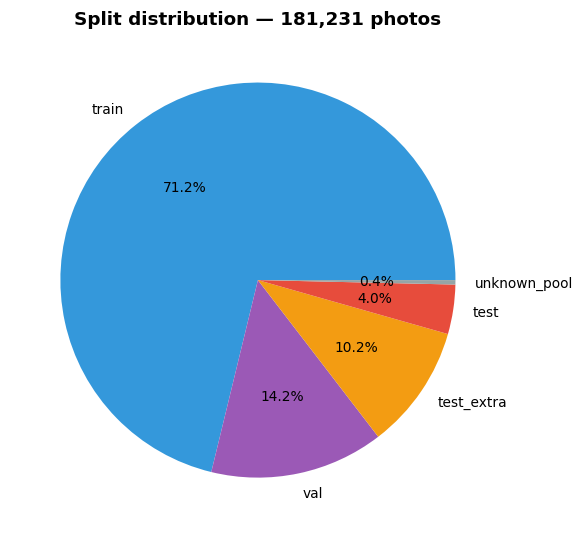

In [136]:
# Overall split distribution
split_counts = df["split"].value_counts()
colors_s = [SPLIT_COLORS.get(s, "#95a5a6") for s in split_counts.index]

fig, ax = plt.subplots(figsize=(7, 5))
wedges, texts, autotexts = ax.pie(
    split_counts.values, labels=split_counts.index,
    autopct="%1.1f%%", colors=colors_s, textprops={"fontsize": 9}
)
ax.set_title("Split distribution — 181,231 photos", fontweight="bold")
plt.tight_layout()
plt.show()

In [137]:
# Key counts per split
for s in ["train", "val", "test", "test_extra", "unknown_pool"]:
    n = (df["split"] == s).sum()
    print(f"  {s:<15} {n:>8,}  ({n/len(df)*100:.1f}%)")

  train            129,241  (71.2%)
  val               25,803  (14.2%)
  test               7,338  (4.0%)
  test_extra        18,465  (10.2%)
  unknown_pool         656  (0.4%)


The 71/14/4/10/0.4 split (train/val/test_extra/test/unknown) is roughly 70-15-15 when train/test are considered. Val and test are both photographer-exclusive — no observer appears in more than one partition.

---
## 3. Species Distribution

How many photos per species?

In [138]:
species_counts = df.groupby("species").size().sort_values(ascending=False)
who_map = df.drop_duplicates("species").set_index("species")["who_category"]
print(f"Total species in dataset: {len(species_counts)}")
print(f"Min: {species_counts.min()}  Median: {species_counts.median():.0f}  Max: {species_counts.max()}")

Total species in dataset: 289
Min: 1  Median: 79  Max: 18340


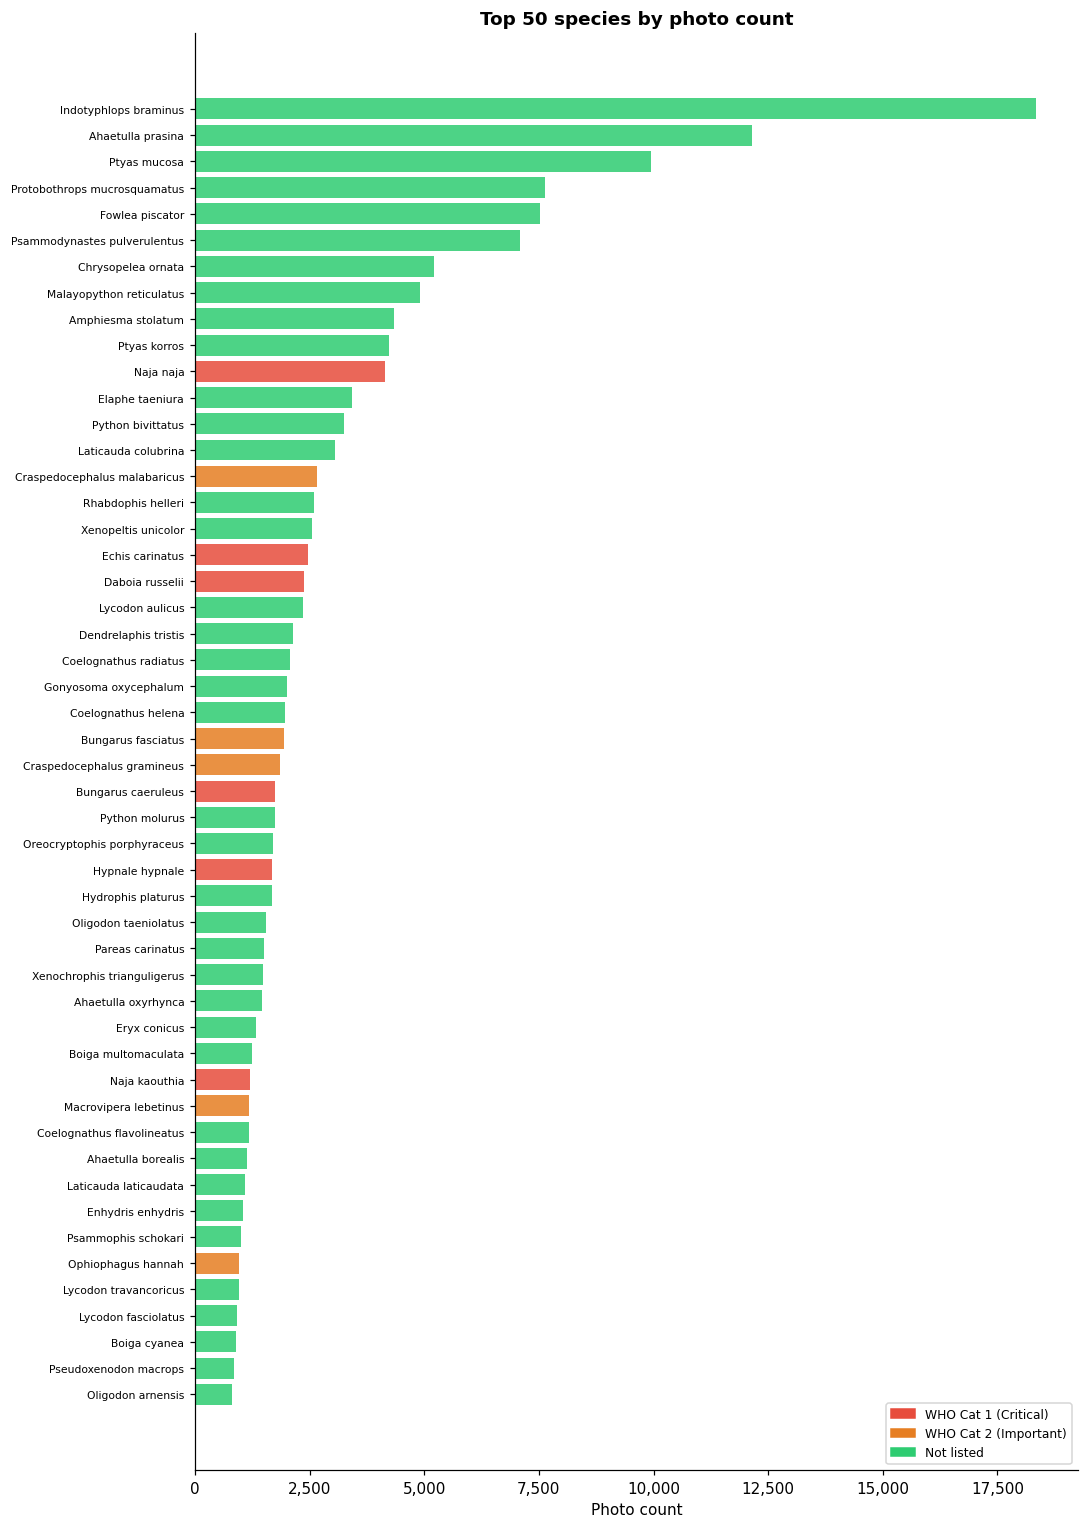

In [139]:
# Top-50 species, coloured by WHO danger category
top50 = species_counts.head(50)
bar_colors = [WHO_COLORS.get(who_map.get(sp, "not_listed"), "#2ecc71") for sp in top50.index]
handles = [mpatches.Patch(color=c, label=WHO_LABELS[k]) for k, c in WHO_COLORS.items()]

fig, ax = plt.subplots(figsize=(10, 14))
ax.barh(range(len(top50)), top50.values[::-1], color=bar_colors[::-1], alpha=0.85)
ax.set_yticks(range(len(top50)))
ax.set_yticklabels([sp.replace("_", " ") for sp in top50.index[::-1]], fontsize=7)
ax.set_xlabel("Photo count")
ax.set_title("Top 50 species by photo count", fontweight="bold")
ax.xaxis.set_major_formatter(FMT)
ax.legend(handles=handles, loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

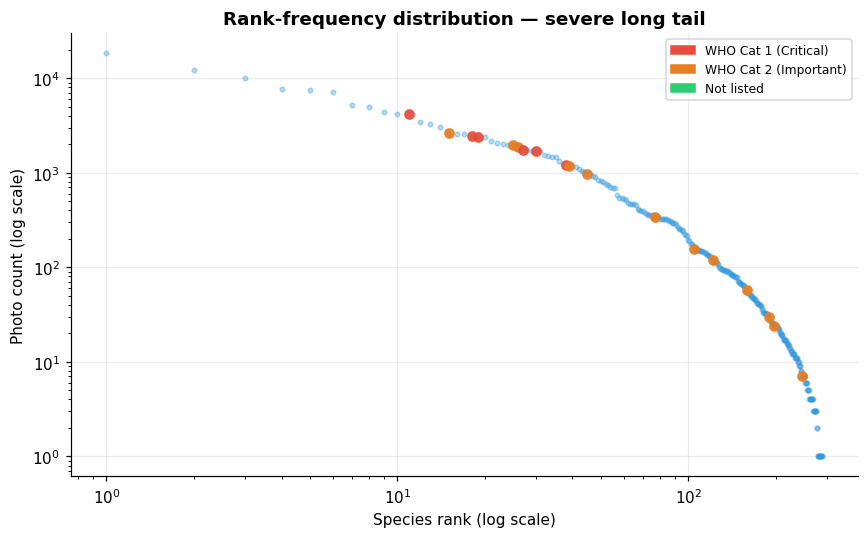

In [140]:
# Rank-frequency log-log plot (long-tail distribution)
ranks = np.arange(1, len(species_counts) + 1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(ranks, species_counts.values, "o", markersize=3, alpha=0.35, color="#3498db")
for i, (sp, cnt) in enumerate(species_counts.items()):
    cat = who_map.get(sp, "not_listed")
    if cat in ["1", "2"]:
        ax.loglog(i + 1, cnt, "o", markersize=6, color=WHO_COLORS[cat], alpha=0.9)
ax.set_xlabel("Species rank (log scale)")
ax.set_ylabel("Photo count (log scale)")
ax.set_title("Rank-frequency distribution — severe long tail", fontweight="bold")
ax.legend(handles=handles, fontsize=8)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [141]:
# How many classes fall below common training-size thresholds?
print(f"{'Threshold':>12}  {'Classes below':>14}  {'%':>6}")
print("-" * 38)
for t in [20, 50, 100, 200, 400, 1000]:
    n = (species_counts < t).sum()
    print(f"< {t:>9,}  {n:>14,}  {n/len(species_counts)*100:>5.1f}%")

   Threshold   Classes below       %
--------------------------------------
<        20              81   28.0%
<        50             124   42.9%
<       100             161   55.7%
<       200             190   65.7%
<       400             221   76.5%
<     1,000             245   84.8%


The distribution is a classic long tail. Fewer than half the species have over 100 photos. Tier-1 (68 species with ≥ 400 photos) will drive most of the model's accuracy; tier-2 will need few-shot or data-augmentation strategies.

---
## 4. Taxonomic Hierarchy

Family → genus → species structure of the 208 classes.

In [142]:
family_photos  = df.groupby("family").size().sort_values(ascending=False)
family_species = df.drop_duplicates("species").groupby("family").size()
print(f"Families in dataset: {len(family_photos)}")
family_photos.head(10)

Families in dataset: 14


family
Colubridae          91638
Viperidae           22698
Typhlopidae         18914
Elapidae            18618
Pythonidae           9913
Psammodynastidae     7094
Homalopsidae         2732
Xenopeltidae         2563
Boidae               2392
Pareidae             1841
dtype: int64

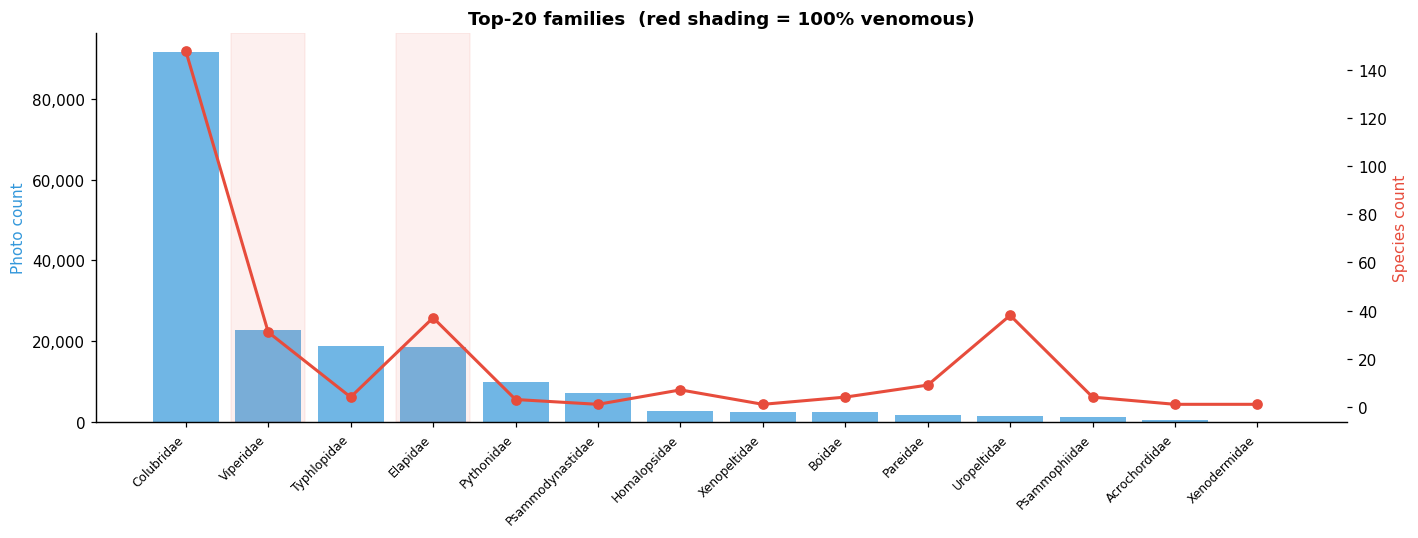

In [143]:
# Family dual-axis: photos (bar) + species count (line)
top_fams = family_photos.head(20).index
x = np.arange(len(top_fams))

fig, ax1 = plt.subplots(figsize=(13, 5))
ax2 = ax1.twinx()

ax1.bar(x, family_photos[top_fams].values, alpha=0.7, color="#3498db", label="Photos")
ax2.plot(x, family_species[top_fams].values, "o-", color="#e74c3c",
         linewidth=2, markersize=6, label="Species")

# Shade venomous families
for i, fam in enumerate(top_fams):
    if fam in ["Viperidae", "Elapidae"]:
        ax1.axvspan(i - 0.45, i + 0.45, alpha=0.08, color="#e74c3c")

ax1.set_xticks(x)
ax1.set_xticklabels(top_fams, rotation=45, ha="right", fontsize=8)
ax1.set_ylabel("Photo count", color="#3498db")
ax2.set_ylabel("Species count", color="#e74c3c")
ax1.set_title("Top-20 families  (red shading = 100% venomous)", fontweight="bold")
ax1.yaxis.set_major_formatter(FMT)
plt.tight_layout()
plt.show()

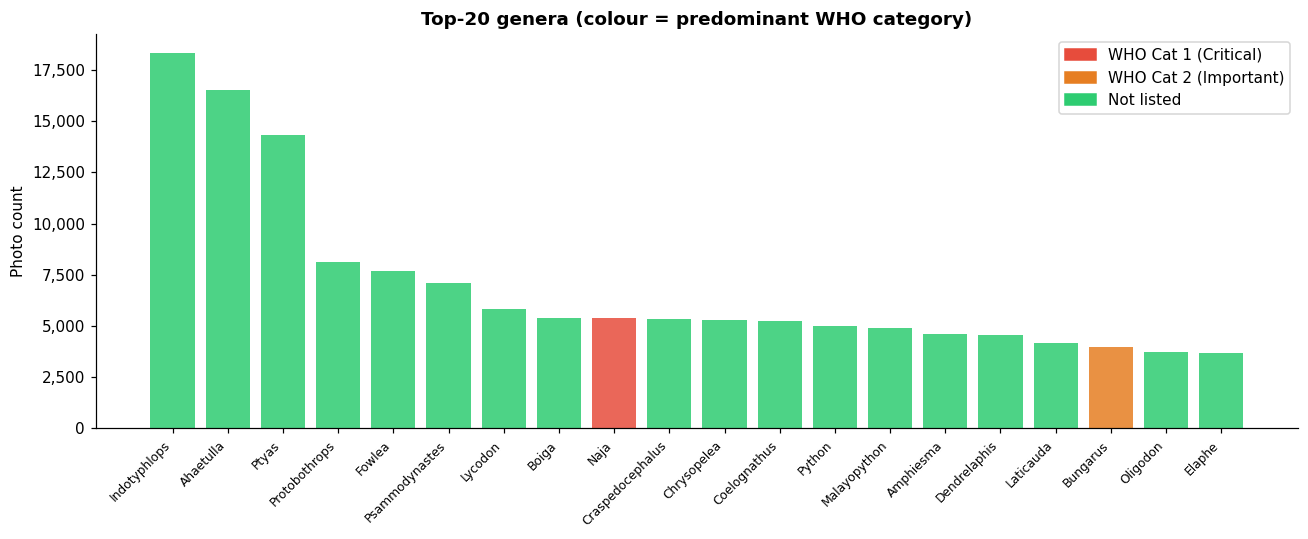

In [144]:
# Top-20 genera, coloured by predominant WHO category
genus_photos = df.groupby("genus").size().sort_values(ascending=False).head(20)
genus_who = (
    df.drop_duplicates("species")
    .groupby("genus")["who_category"]
    .apply(lambda x: x.mode()[0])
    .to_dict()
)
g_colors = [WHO_COLORS.get(genus_who.get(g, "not_listed"), "#2ecc71") for g in genus_photos.index]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(genus_photos.index, genus_photos.values, color=g_colors, alpha=0.85)
ax.set_xticklabels(genus_photos.index, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Photo count")
ax.set_title("Top-20 genera (colour = predominant WHO category)", fontweight="bold")
ax.yaxis.set_major_formatter(FMT)
ax.legend(handles=handles, loc="upper right")
plt.tight_layout()
plt.show()

Colubridae dominates in species count but Viperidae and Elapidae (the two 100%-venomous families) still contribute meaningful photo volume — important for the model.

---
## 5. WHO Safety Categories

WHO SEARO 2016 — India snakebite guidelines (pages 86-87).

In [145]:
who_photo_counts   = df["who_category"].value_counts()
who_species_counts = df.drop_duplicates("species")["who_category"].value_counts()
print("Photos per WHO category:")
for k, n in who_photo_counts.items():
    print(f"  {WHO_LABELS.get(k, k):<35} {n:>8,}  ({n/len(df)*100:.1f}%)")

Photos per WHO category:
  Not listed                           158,510  (87.3%)
  WHO Cat 1 (Critical)                  13,643  (7.5%)
  WHO Cat 2 (Important)                  9,350  (5.2%)


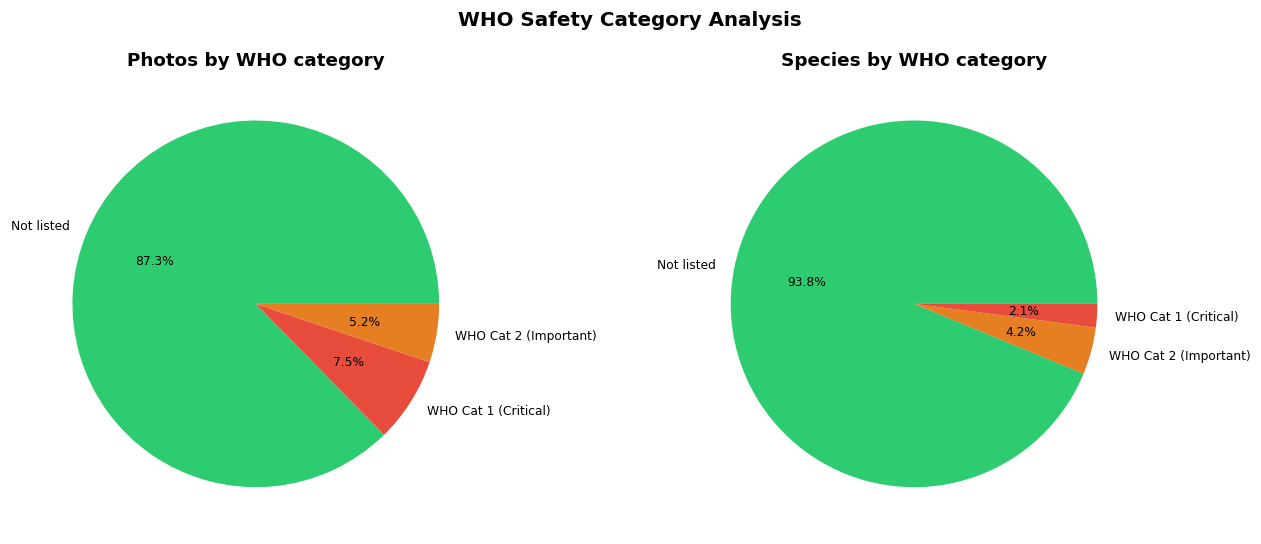

In [146]:
# Pie: photos by WHO category
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, data, title in [
    (axes[0], who_photo_counts,   "Photos by WHO category"),
    (axes[1], who_species_counts, "Species by WHO category"),
]:
    colors_p = [WHO_COLORS.get(k, "#95a5a6") for k in data.index]
    ax.pie(data.values,
           labels=[WHO_LABELS.get(k, k) for k in data.index],
           autopct="%1.1f%%", colors=colors_p, textprops={"fontsize": 8})
    ax.set_title(title, fontweight="bold")
fig.suptitle("WHO Safety Category Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [147]:
# Category 1 species — the highest-priority group
cat1 = (
    df[df["who_category"] == "1"]
    .groupby("species").size()
    .sort_values(ascending=False)
    .reset_index(name="photos")
    .merge(df.drop_duplicates("species")[["species","genus","family"]], on="species")
)
print("WHO Category 1 species (must-get-right):")
cat1[["species","genus","family","photos"]]

WHO Category 1 species (must-get-right):


,species,genus,family,photos
0,Naja naja,Naja,Elapidae,4137
1,Echis carinatus,Echis,Viperidae,2473
2,Daboia russelii,Daboia,Viperidae,2386
3,Bungarus caeruleus,Bungarus,Elapidae,1755
4,Hypnale hypnale,Hypnale,Viperidae,1690
5,Naja kaouthia,Naja,Elapidae,1202


In [148]:
# Category 2 species
cat2 = (
    df[df["who_category"] == "2"]
    .groupby("species").size()
    .sort_values(ascending=False)
    .reset_index(name="photos")
    .merge(df.drop_duplicates("species")[["species","genus","family"]], on="species")
)
print("WHO Category 2 species:")
cat2[["species","genus","family","photos"]]

WHO Category 2 species:


,species,genus,family,photos
0,Craspedocephalus malabaricus,Craspedocephalus,Viperidae,2663
1,Bungarus fasciatus,Bungarus,Elapidae,1950
2,Craspedocephalus gramineus,Craspedocephalus,Viperidae,1850
3,Macrovipera lebetinus,Macrovipera,Viperidae,1182
4,Ophiophagus hannah,Ophiophagus,Elapidae,970
5,Trimeresurus erythrurus,Trimeresurus,Viperidae,342
6,Ophiophagus kaalinga,Ophiophagus,Elapidae,155
7,Bungarus niger,Bungarus,Elapidae,120
8,Naja oxiana,Naja,Elapidae,57
9,Bungarus walli,Bungarus,Elapidae,30


Category 1 contains the Big Six: Indian cobra, common krait, Russell's viper, saw-scaled viper, king cobra, and hump-nosed viper. These 6 species cause >95% of snakebite deaths in India — maximum recall on these is non-negotiable.

---
## 6. Tier Analysis

`tier1` ≥ 400 photos (68 species) · `tier2` 20-399 photos (140 species) · unknown_pool < 20 (81 species)

In [149]:
tier_summary = df.groupby("tier").agg(
    photos=("species", "count"),
    species=("species", "nunique"),
)
tier_summary["avg_photos_per_species"] = tier_summary["photos"] / tier_summary["species"]
tier_summary

,photos,species,avg_photos_per_species
tier,,,
tier1,162999,68,2397.044118
tier2,17848,140,127.485714
unknown_pool,656,81,8.098765


In [194]:
# Tier bar chart
tier_order  = ["tier1", "tier2", "unknown_pool"]
tier_labels = ["Tier 1
(≥400 photos, 68 sp)", "Tier 2
(20-399, 140 sp)", "Unknown pool
(<20, 81 sp)"]
tier_colors = ["#2ecc71", "#f39c12", "#95a5a6"]
vals = [tier_summary.loc[t, "photos"] if t in tier_summary.index else 0 for t in tier_order]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bars = axes[0].bar(tier_labels, vals, color=tier_colors, alpha=0.85)
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
                 f"{int(bar.get_height()):,}", ha="center", fontsize=9)
axes[0].set_ylabel("Photo count")
axes[0].set_title("Photos per tier", fontweight="bold")
axes[0].yaxis.set_major_formatter(FMT)

# Tier-1 per-species distribution
tier1_counts = df[df["tier"] == "tier1"].groupby("species").size()
axes[1].hist(tier1_counts.values, bins=20, color="#2ecc71", alpha=0.8, edgecolor="white")
axes[1].axvline(tier1_counts.mean(), color="#e74c3c", linestyle="--",
                label=f"Mean {tier1_counts.mean():.0f}")
axes[1].set_xlabel("Photos per species")
axes[1].set_title("Tier-1 per-species histogram", fontweight="bold")
axes[1].legend()
plt.tight_layout()
plt.show()

SyntaxError: unterminated string literal (detected at line 3) (707040234.py, line 3)

In [152]:
# Core-27: the Milestone 1 baseline species
if "m1_core27" in df.columns:
    core27 = df[df["m1_core27"] == True].drop_duplicates("species").copy()
    core27["total_photos"] = core27["species"].map(df.groupby("species").size())
    core27 = core27.sort_values("total_photos", ascending=False)[
        ["species","genus","who_category","tier","total_photos"]
    ]
    print(f"Core-27 species ({len(core27)} total):")
    display(core27)

Core-27 species (27 total):


,species,genus,who_category,tier,total_photos
27504,Indotyphlops braminus,Indotyphlops,not_listed,tier1,18340
5938,Ptyas mucosa,Ptyas,not_listed,tier1,9943
0,Fowlea piscator,Fowlea,not_listed,tier1,7524
19273,Amphiesma stolatum,Amphiesma,not_listed,tier1,4351
13846,Naja naja,Naja,1,tier1,4137
17202,Craspedocephalus malabaricus,Craspedocephalus,2,tier1,2663
47391,Echis carinatus,Echis,1,tier1,2473
22473,Daboia russelii,Daboia,1,tier1,2386
25770,Lycodon aulicus,Lycodon,not_listed,tier1,2362
45717,Dendrelaphis tristis,Dendrelaphis,not_listed,tier1,2148


All 27 M1 species are present. The core-27 includes all 6 WHO Category 1 species, ensuring the safety-critical classes are well represented even before tier-2 augmentation.

---
## 7. Train / Val / Test Split Validation

Split strategy: StratifiedGroupKFold on `observer_id`.

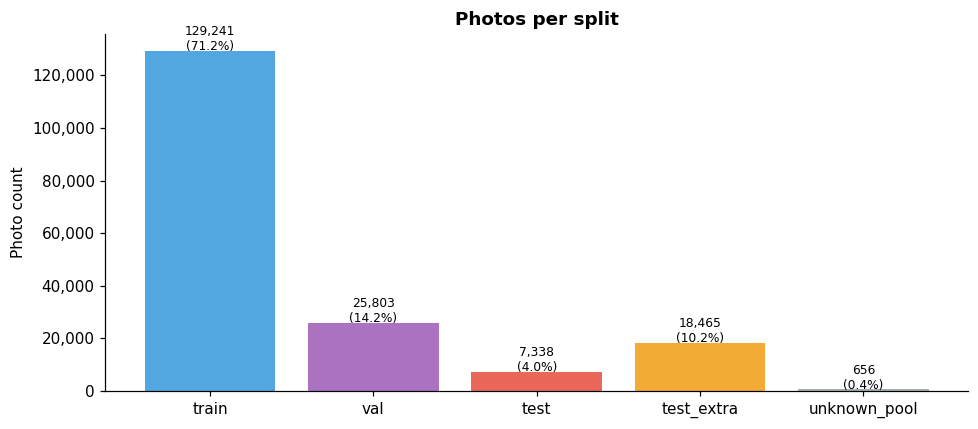

In [195]:
split_counts = df["split"].value_counts()

split_order = [
    s for s in ["train", "val", "test", "test_extra", "unknown_pool"]
    if s in split_counts.index
]

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.bar(
    split_order,
    [split_counts[s] for s in split_order],
    color=[SPLIT_COLORS.get(s, "#95a5a6") for s in split_order],
    alpha=0.85,
)

for bar in bars:
    count = int(bar.get_height())
    percentage = count / len(df) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 300,
        f"{count:,}\n({percentage:.1f}%)",
        ha="center",
        fontsize=8,
    )

ax.set_ylabel("Photo count")
ax.set_title("Photos per split", fontweight="bold")
ax.yaxis.set_major_formatter(FMT)

plt.tight_layout()
plt.show()

In [154]:
# Photographer isolation check
train_obs = set(df[df["split"]=="train"]["observer_id"].dropna())
val_obs   = set(df[df["split"]=="val"]["observer_id"].dropna())
test_obs  = set(df[df["split"]=="test"]["observer_id"].dropna())

overlaps = {
    "Train ∩ Val":  len(train_obs & val_obs),
    "Train ∩ Test": len(train_obs & test_obs),
    "Val ∩ Test":   len(val_obs   & test_obs),
}
for key, val in overlaps.items():
    status = "✓ zero overlap" if val == 0 else f"✗ {val} shared observers"
    print(f"  {key:<18} {status}")

  Train ∩ Val        ✓ zero overlap
  Train ∩ Test       ✓ zero overlap
  Val ∩ Test         ✓ zero overlap


In [155]:
# Temporal boundary: test set should be from 2022 onwards
print("Year distribution per split:")
for s in ["train","val","test","test_extra"]:
    yrs = df[df["split"]==s]["year"].dropna()
    post22 = (yrs >= 2022).mean() * 100
    print(f"  {s:<15}  {yrs.min():.0f}–{yrs.max():.0f}  ({post22:.0f}% from 2022+)")

Year distribution per split:
  train            1968–2026  (77% from 2022+)
  val              1980–2026  (76% from 2022+)
  test             1970–2026  (87% from 2022+)
  test_extra       1990–2026  (64% from 2022+)


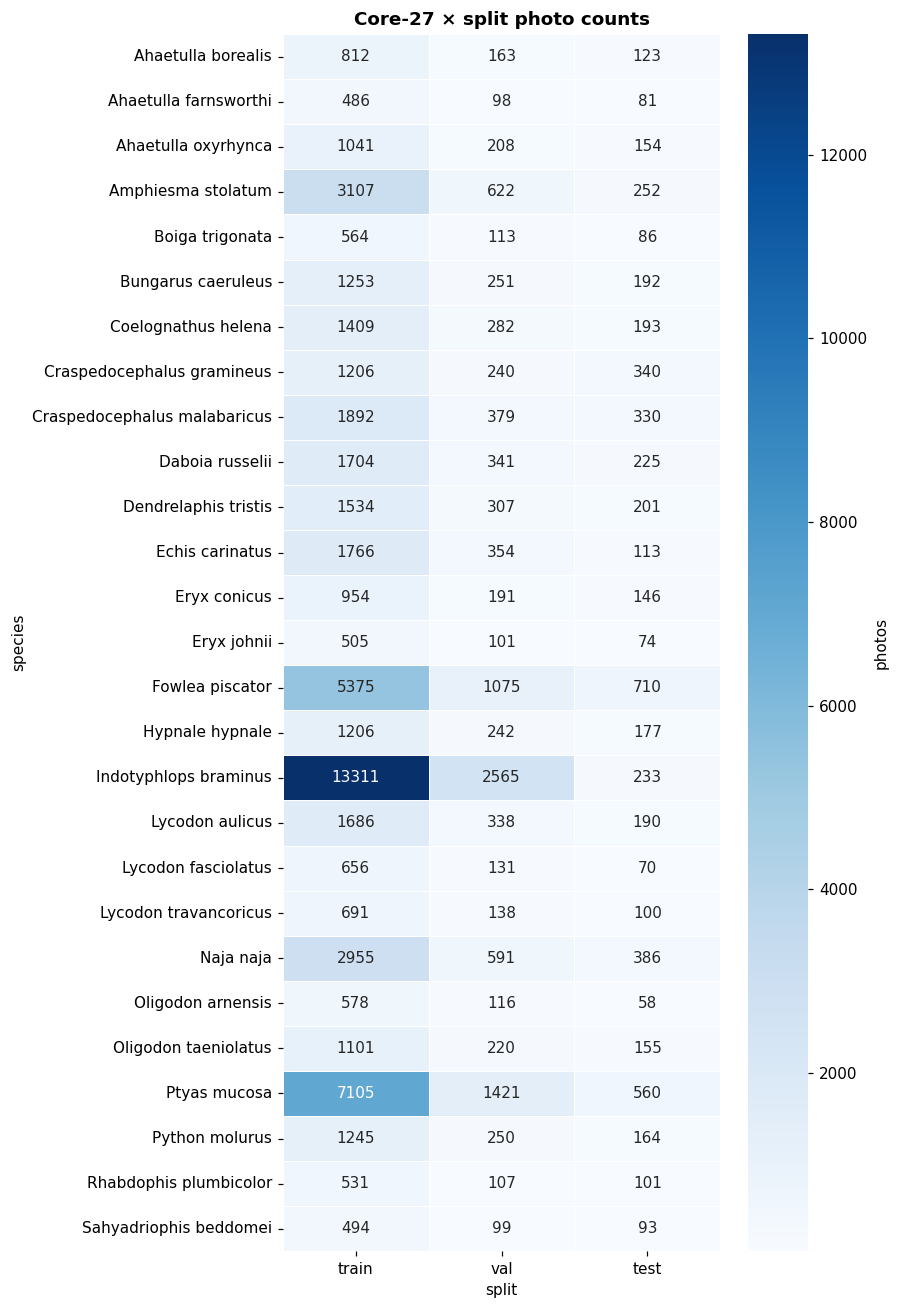

In [156]:
# Core-27 per-split heatmap
if "m1_core27" in df.columns:
    core_hm = (
        df[df["m1_core27"] == True]
        .groupby(["species","split"]).size()
        .unstack(fill_value=0)
    )
    cols = [c for c in ["train","val","test"] if c in core_hm.columns]
    fig, ax = plt.subplots(figsize=(8, 12))
    sns.heatmap(core_hm[cols], annot=True, fmt="d", cmap="Blues",
                linewidths=0.5, cbar_kws={"label":"photos"}, ax=ax)
    ax.set_title("Core-27 × split photo counts", fontweight="bold")
    plt.tight_layout()
    plt.show()

All overlaps are zero — the dataset passes the photographer leakage test. Test photos are skewed to 2022+ to simulate a real-world deployment gap (model trained on older data, tested on newer).

---
## 8. Image Quality Analysis

In [157]:
df["kb"]     = df["bytes"] / 1024
df["aspect"] = (df["width"] / df["height"].replace(0, np.nan)).clip(0.1, 10)
print(f"Width:   min={df['width'].min():.0f}  median={df['width'].median():.0f}  max={df['width'].max():.0f} px")
print(f"Height:  min={df['height'].min():.0f}  median={df['height'].median():.0f}  max={df['height'].max():.0f} px")
print(f"Size:    min={df['kb'].min():.1f}  median={df['kb'].median():.1f}  max={df['kb'].max():.1f} KB")

Width:   min=116  median=500  max=500 px
Height:  min=100  median=375  max=500 px
Size:    min=4.9  median=124.9  max=25542.6 KB


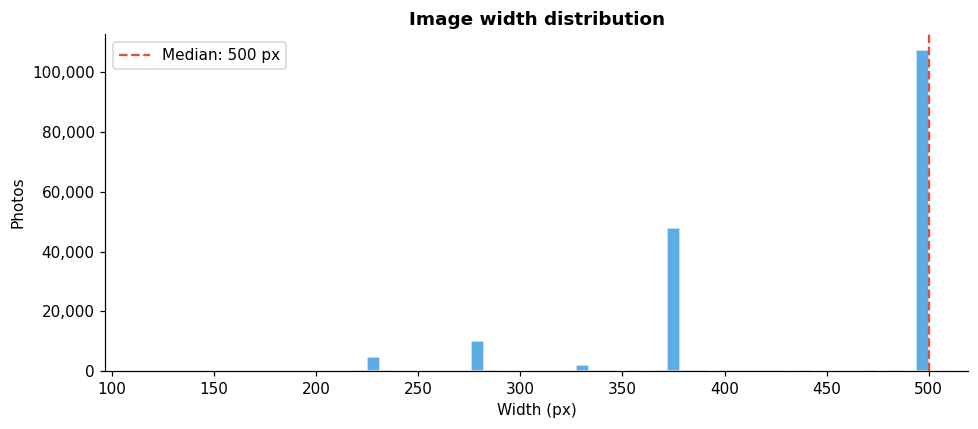

In [158]:
# Width distribution
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df["width"].dropna(), bins=60, color="#3498db", alpha=0.8, edgecolor="white")
ax.axvline(df["width"].median(), color="#e74c3c", linestyle="--",
           label=f"Median: {df['width'].median():.0f} px")
ax.set_xlabel("Width (px)")
ax.set_ylabel("Photos")
ax.set_title("Image width distribution", fontweight="bold")
ax.yaxis.set_major_formatter(FMT)
ax.legend()
plt.tight_layout()
plt.show()

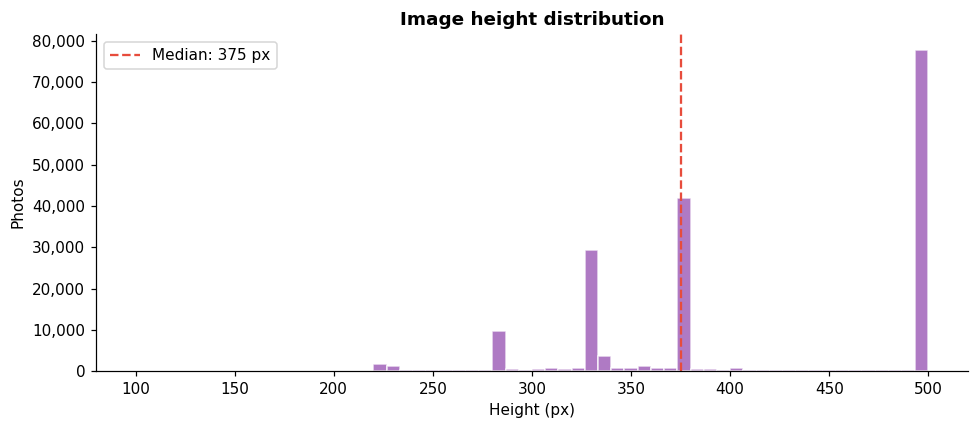

In [159]:
# Height distribution
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df["height"].dropna(), bins=60, color="#9b59b6", alpha=0.8, edgecolor="white")
ax.axvline(df["height"].median(), color="#e74c3c", linestyle="--",
           label=f"Median: {df['height'].median():.0f} px")
ax.set_xlabel("Height (px)")
ax.set_ylabel("Photos")
ax.set_title("Image height distribution", fontweight="bold")
ax.yaxis.set_major_formatter(FMT)
ax.legend()
plt.tight_layout()
plt.show()

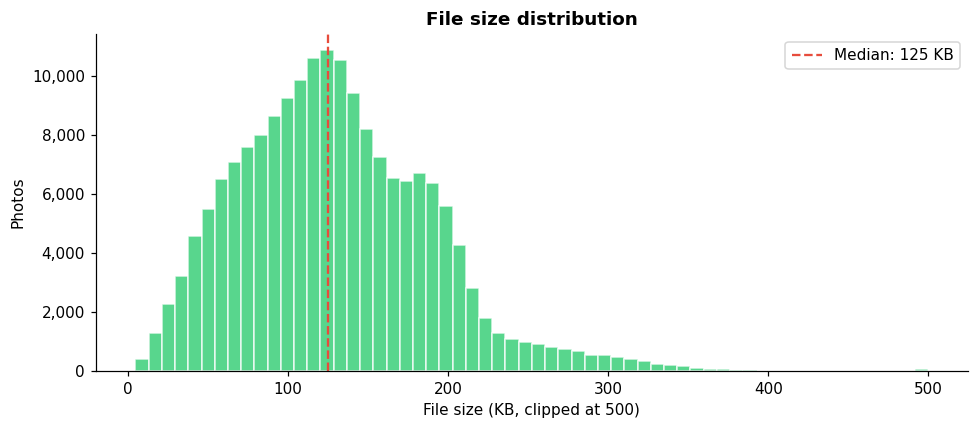

In [160]:
# File size distribution (clipped at 500 KB for readability)
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df["kb"].clip(upper=500).dropna(), bins=60, color="#2ecc71", alpha=0.8, edgecolor="white")
ax.axvline(df["kb"].median(), color="#e74c3c", linestyle="--",
           label=f"Median: {df['kb'].median():.0f} KB")
ax.set_xlabel("File size (KB, clipped at 500)")
ax.set_ylabel("Photos")
ax.set_title("File size distribution", fontweight="bold")
ax.yaxis.set_major_formatter(FMT)
ax.legend()
plt.tight_layout()
plt.show()

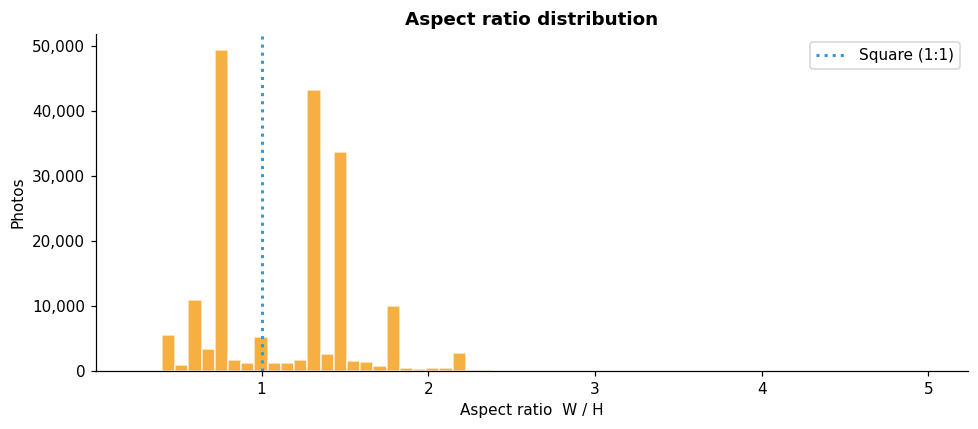

In [161]:
# Aspect ratio histogram
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df["aspect"].dropna(), bins=60, color="#f39c12", alpha=0.8, edgecolor="white")
ax.axvline(1.0, color="#3498db", linestyle=":", linewidth=2, label="Square (1:1)")
ax.set_xlabel("Aspect ratio  W / H")
ax.set_ylabel("Photos")
ax.set_title("Aspect ratio distribution", fontweight="bold")
ax.yaxis.set_major_formatter(FMT)
ax.legend()
plt.tight_layout()
plt.show()

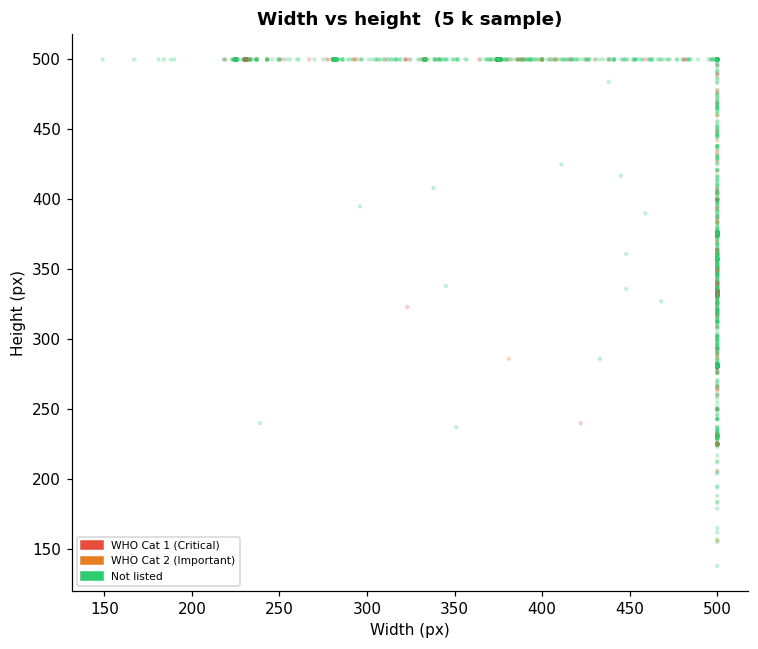

In [162]:
# Width vs height scatter (5 k sample, coloured by WHO)
samp   = df.dropna(subset=["width","height"]).sample(min(5000, len(df)), random_state=42)
samp_c = [WHO_COLORS.get(samp.loc[i, "who_category"], "#2ecc71") for i in samp.index]

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(samp["width"], samp["height"], c=samp_c, alpha=0.2, s=4)
ax.set_xlabel("Width (px)")
ax.set_ylabel("Height (px)")
ax.set_title("Width vs height  (5 k sample)", fontweight="bold")
ax.legend(handles=handles, fontsize=7)
plt.tight_layout()
plt.show()

In [163]:
# Photos below common model input thresholds
short_side = df[["width","height"]].min(axis=1)
print(f"{'Min side < threshold':>24}  {'Photos':>8}  {'%':>6}")
print("-" * 44)
for t in [100, 224, 256, 320, 500]:
    n   = (short_side < t).sum()
    pct = n / len(df) * 100
    print(f"  < {t:>4} px              {n:>8,}  {pct:>5.1f}%")

    Min side < threshold    Photos       %
--------------------------------------------
  <  100 px                     0    0.0%
  <  224 px                 1,216    0.7%
  <  256 px                10,824    6.0%
  <  320 px                35,799   19.7%
  <  500 px               177,825   98.0%


Most images are in the 400-500 px range (iNaturalist 'medium' size). Only ~1% are smaller than 224 px. Standard 224 × 224 or 384 × 384 training resolution should cover >99% of photos without upscaling artefacts.

---
## 9. Geographic Distribution

In [165]:
geo_df = df.dropna(subset=["latitude","longitude"])
india  = geo_df[geo_df["latitude"].between(6, 38) & geo_df["longitude"].between(68, 98)]
print(f"Photos with coordinates:  {len(geo_df):,}  ({len(geo_df)/len(df)*100:.1f}%)")
print(f"Within India bounding box: {len(india):,}  ({len(india)/len(df)*100:.1f}%)")
print(f"Obscured / no coord:       {df['latitude'].isna().sum():,}  ({df['latitude'].isna().mean()*100:.1f}%)")

Photos with coordinates:  180,008  (99.2%)
Within India bounding box: 75,306  (41.5%)
Obscured / no coord:       1,495  (0.8%)


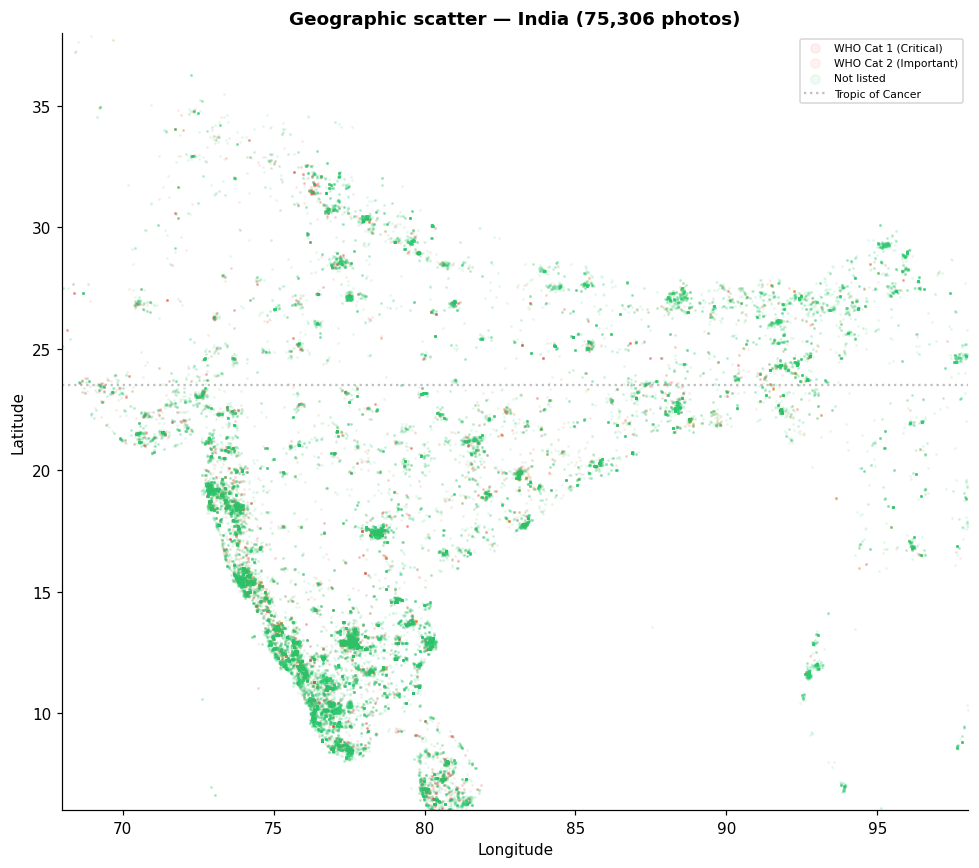

In [166]:
# Scatter map — India bounding box
fig, ax = plt.subplots(figsize=(9, 8))
for cat, color in WHO_COLORS.items():
    mask = india["who_category"] == cat
    ax.scatter(india.loc[mask, "longitude"], india.loc[mask, "latitude"],
               c=color, alpha=0.08, s=1, label=WHO_LABELS[cat])
ax.axhline(23.5, color="gray", linestyle=":", alpha=0.5, label="Tropic of Cancer")
ax.set_xlim(68, 98)
ax.set_ylim(6, 38)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"Geographic scatter — India ({len(india):,} photos)", fontweight="bold")
ax.legend(fontsize=7, markerscale=6)
plt.tight_layout()
plt.show()

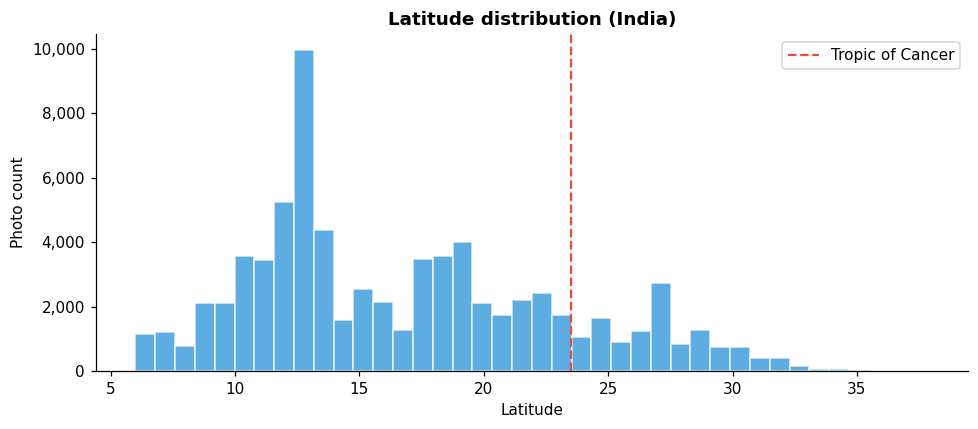

In [167]:
# Latitude histogram — south vs north India
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(india["latitude"], bins=40, color="#3498db", alpha=0.8,
        edgecolor="white", orientation="vertical")
ax.axvline(23.5, color="#e74c3c", linestyle="--", label="Tropic of Cancer")
ax.set_xlabel("Latitude")
ax.set_ylabel("Photo count")
ax.set_title("Latitude distribution (India)", fontweight="bold")
ax.yaxis.set_major_formatter(FMT)
ax.legend()
plt.tight_layout()
plt.show()

Western Ghats (lat ~8-15, lon ~75-77) and the Gangetic plains (lat ~22-27) show the highest density. The Northeast, despite high biodiversity, is underrepresented — likely fewer iNaturalist users, not fewer snakes.

---
## 10. Temporal Distribution & Seasonality

In [168]:
year_counts = df["year"].dropna().astype(int).value_counts().sort_index()
print("Photos per year (recent 10):")
print(year_counts.tail(10).to_string())

Photos per year (recent 10):
year
2017     2713
2018     4228
2019     6213
2020     8532
2021    12139
2022    15985
2023    22349
2024    29016
2025    35283
2026    34749


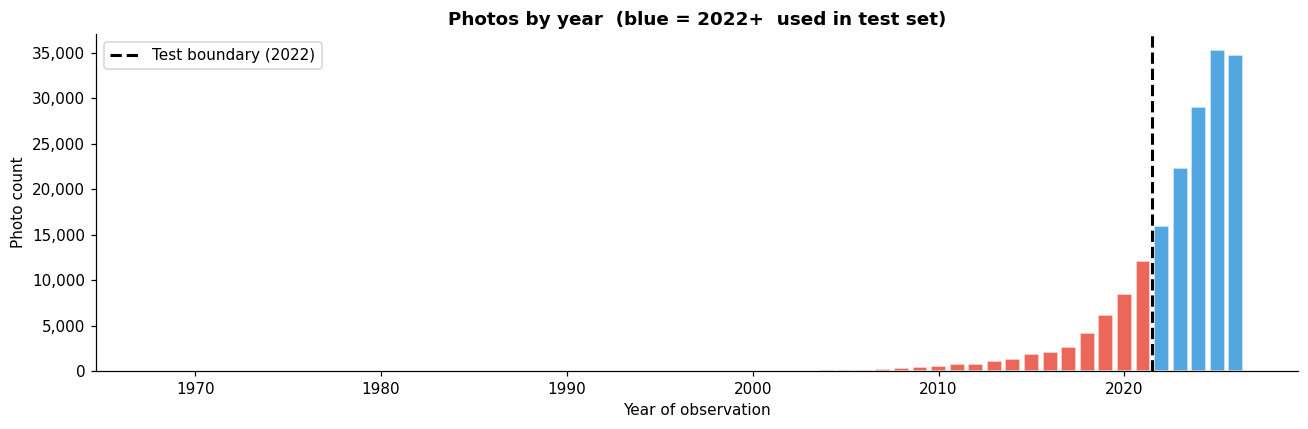

In [169]:
# Year histogram — colour pre/post 2022 test boundary
bar_c = ["#e74c3c" if y < 2022 else "#3498db" for y in year_counts.index]

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(year_counts.index, year_counts.values, color=bar_c, alpha=0.85, edgecolor="white")
ax.axvline(2021.5, color="black", linestyle="--", linewidth=2, label="Test boundary (2022)")
ax.set_xlabel("Year of observation")
ax.set_ylabel("Photo count")
ax.set_title("Photos by year  (blue = 2022+  used in test set)", fontweight="bold")
ax.yaxis.set_major_formatter(FMT)
ax.legend()
plt.tight_layout()
plt.show()

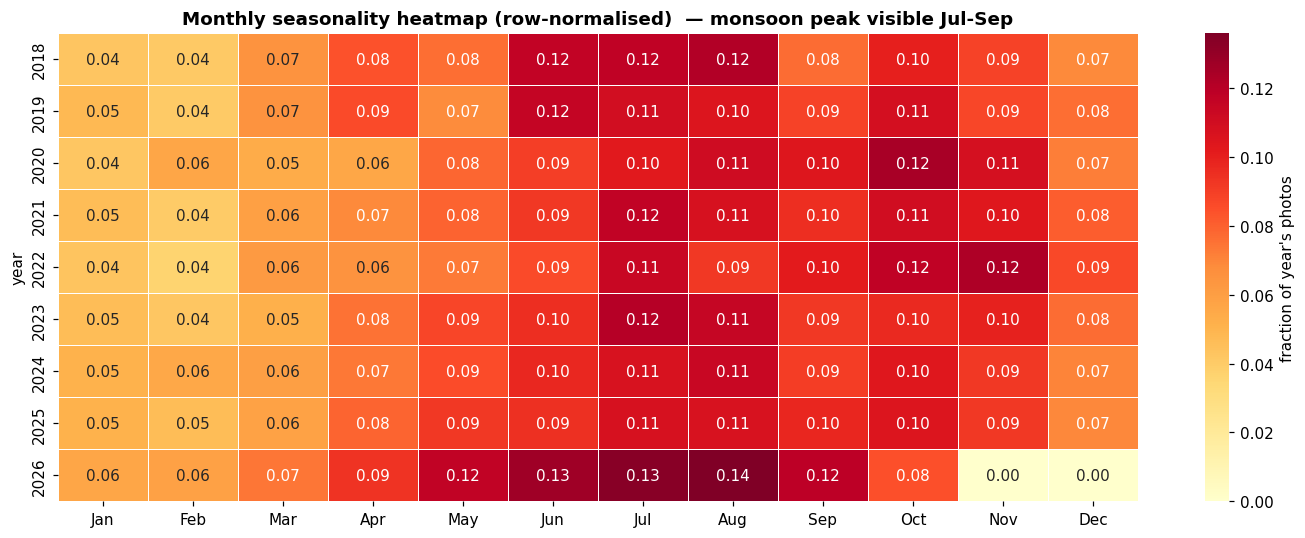

In [170]:
# Monthly seasonality heatmap (2018-2026)
hm_df  = df[(df["year"] >= 2018) & (df["year"] <= 2026)].copy()
hm     = hm_df.groupby(["year","month"]).size().unstack(fill_value=0)
hm_norm = hm.div(hm.sum(axis=1), axis=0)
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
hm_norm.columns = [month_names[m-1] for m in hm_norm.columns]

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(hm_norm, ax=ax, cmap="YlOrRd", annot=True, fmt=".2f",
            linewidths=0.5, cbar_kws={"label": "fraction of year's photos"})
ax.set_title("Monthly seasonality heatmap (row-normalised)  — monsoon peak visible Jul-Sep", fontweight="bold")
plt.tight_layout()
plt.show()

In [171]:
print(f"Earliest observation: {df['observed_on'].min().date()}")
print(f"Latest observation:   {df['observed_on'].max().date()}")
print(f"Photos from 2022+:    {(df['year'] >= 2022).sum():,}  ({(df['year'] >= 2022).mean()*100:.1f}%)")
print(f"Photos pre-2022:      {(df['year'] < 2022).sum():,}  ({(df['year'] < 2022).mean()*100:.1f}%)")

Earliest observation: 1968-03-24
Latest observation:   2026-10-24
Photos from 2022+:    137,382  (75.7%)
Photos pre-2022:      44,121  (24.3%)


Activity peaks in the monsoon (Jun-Sep), consistent with snake emergence during the wet season. This seasonal bias is worth noting for any time-based cross-validation scheme.

---
## 11. Observer & Photographer Diversity

In [172]:
obs_counts = df["observer_id"].value_counts()
print(f"Total photographers:        {len(obs_counts):,}")
print(f"Single-photo photographers: {(obs_counts==1).sum():,}  ({(obs_counts==1).mean()*100:.1f}%)")
print(f"Top photographer (photos):  {obs_counts.max():,}")
obs_counts.describe()

Total photographers:        25,070
Single-photo photographers: 9,634  (38.4%)
Top photographer (photos):  2,191


count    25070.000000
mean         7.239848
std         27.446078
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max       2191.000000
Name: count, dtype: float64

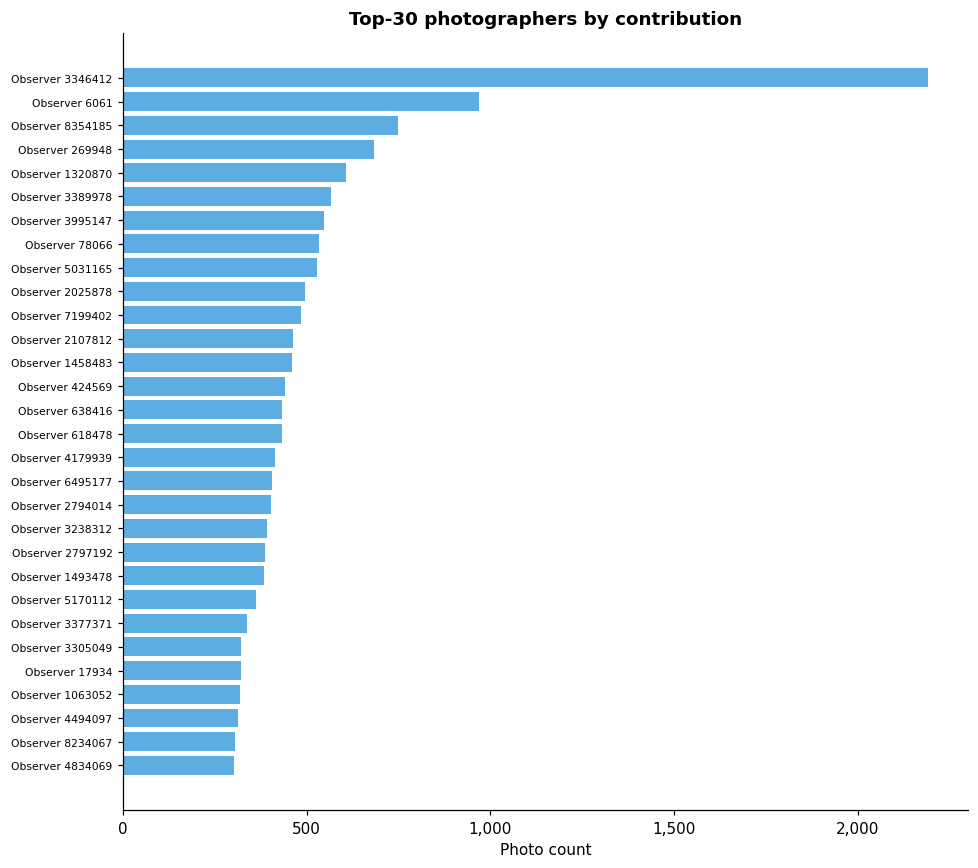

In [173]:
# Top-30 photographers
top30 = obs_counts.head(30)

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(range(len(top30)), top30.values[::-1], color="#3498db", alpha=0.8)
ax.set_yticks(range(len(top30)))
ax.set_yticklabels([f"Observer {str(oid)[:8]}" for oid in top30.index[::-1]], fontsize=7)
ax.set_xlabel("Photo count")
ax.set_title("Top-30 photographers by contribution", fontweight="bold")
ax.xaxis.set_major_formatter(FMT)
plt.tight_layout()
plt.show()

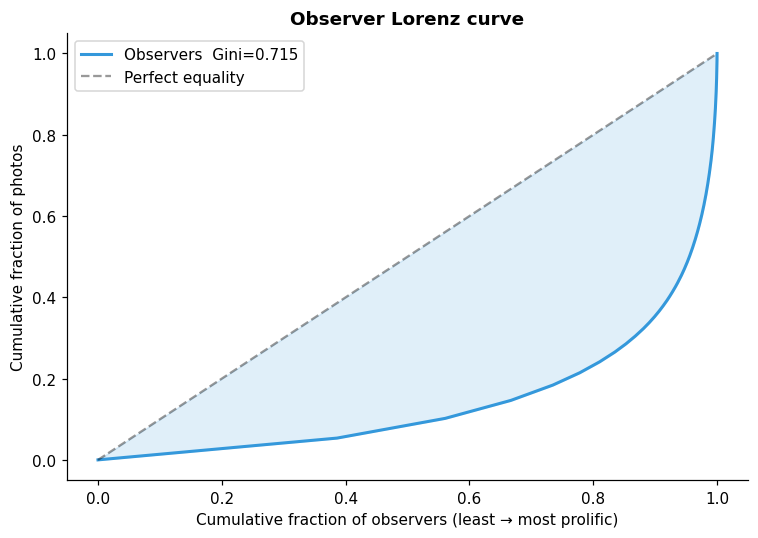

In [174]:
# Lorenz curve — observer concentration
sorted_obs = np.sort(obs_counts.values)
cum_obs    = np.cumsum(sorted_obs) / sorted_obs.sum()
x_obs      = np.linspace(0, 1, len(sorted_obs))
gini_obs   = float(1 - 2 * np.trapz(cum_obs, x_obs))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x_obs, cum_obs, color="#3498db", linewidth=2, label=f"Observers  Gini={gini_obs:.3f}")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Perfect equality")
ax.fill_between(x_obs, x_obs, cum_obs, alpha=0.15, color="#3498db")
ax.set_xlabel("Cumulative fraction of observers (least → most prolific)")
ax.set_ylabel("Cumulative fraction of photos")
ax.set_title("Observer Lorenz curve", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

In [175]:
top1  = obs_counts.head(max(1, len(obs_counts)//100)).sum()
top10 = obs_counts.head(max(1, len(obs_counts)//10)).sum()
print(f"Top  1% of observers → {top1/len(df)*100:.1f}% of all photos")
print(f"Top 10% of observers → {top10/len(df)*100:.1f}% of all photos")
print(f"Observer Gini index:   {gini_obs:.3f}")

Top  1% of observers → 26.6% of all photos
Top 10% of observers → 64.6% of all photos
Observer Gini index:   0.715


High Gini (>0.7 likely) means a small number of prolific photographers dominate the dataset. This creates a risk that the model learns photographer-specific image styles. Heavy augmentation (colour jitter, blur, crop) at training time is essential.

---
## 12. Licence Analysis

In [176]:
lic_counts = df["license"].value_counts()
print("Licence breakdown (from dataset):")
lic_counts

Licence breakdown (from dataset):


license
cc-by-nc               101477
all-rights-reserved     56739
cc-by                   14986
cc-by-nc-nd              2902
cc-by-nc-sa              2628
cc0                      1472
cc-by-sa                 1188
cc-by-nd                  111
Name: count, dtype: int64

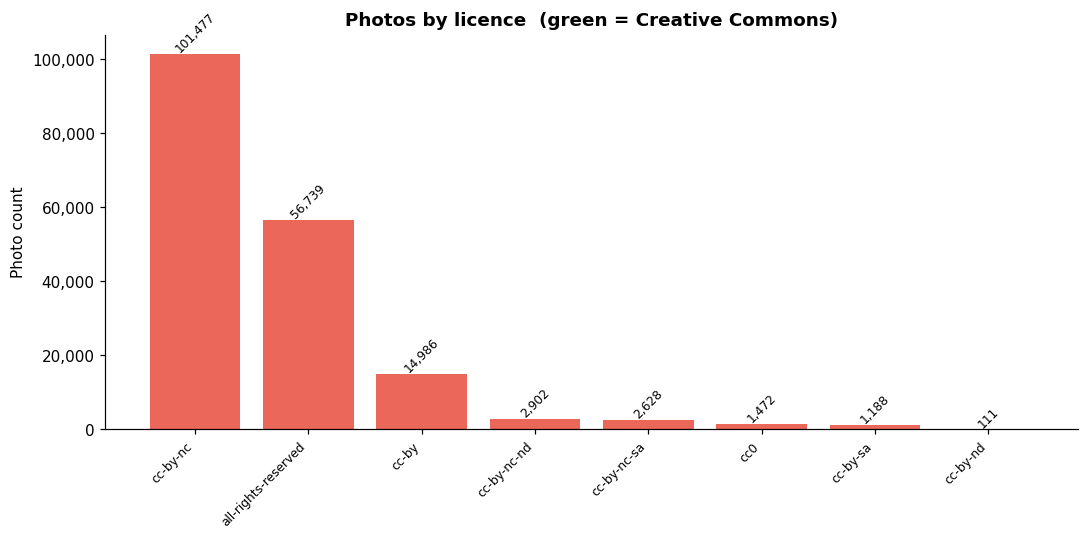

In [177]:
# Licence bar chart
colors_lic = ["#2ecc71" if str(l).startswith("CC") else "#e74c3c" for l in lic_counts.index]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(lic_counts.index, lic_counts.values, color=colors_lic, alpha=0.85)
ax.set_xticklabels(lic_counts.index, rotation=45, ha="right", fontsize=8)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 400,
            f"{int(bar.get_height()):,}", ha="center", fontsize=8, rotation=45)
ax.set_ylabel("Photo count")
ax.set_title("Photos by licence  (green = Creative Commons)", fontweight="bold")
ax.yaxis.set_major_formatter(FMT)
plt.tight_layout()
plt.show()

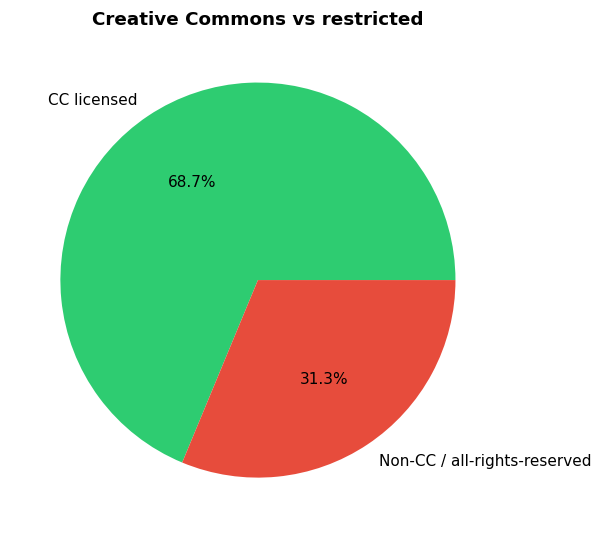

In [178]:
# CC vs non-CC
if "cc_licensed" in df.columns:
    cc_yes = df["cc_licensed"].sum()
    cc_no  = len(df) - cc_yes
else:
    cc_yes = lic_counts[lic_counts.index.str.startswith("CC")].sum()
    cc_no  = len(df) - cc_yes

fig, ax = plt.subplots(figsize=(6, 5))
ax.pie([cc_yes, cc_no], labels=["CC licensed", "Non-CC / all-rights-reserved"],
       autopct="%1.1f%%", colors=["#2ecc71", "#e74c3c"])
ax.set_title("Creative Commons vs restricted", fontweight="bold")
plt.tight_layout()
plt.show()

In [179]:
# M2 report exact counts
report_lic = [
    ("CC BY-NC",            101308, 55.7),
    ("All rights reserved",  56662, 31.1),
    ("CC BY",                14964,  8.2),
    ("CC BY-NC-ND",           2902,  1.6),
    ("CC BY-NC-SA",           2628,  1.4),
    ("CC0",                   1471,  0.8),
    ("CC BY-SA",              1185,  0.7),
    ("CC BY-ND",               111,  0.1),
]
lic_df = pd.DataFrame(report_lic, columns=["Licence","Photos","Share%"])
lic_df

,Licence,Photos,Share%
0,CC BY-NC,101308,55.7
1,All rights reserved,56662,31.1
2,CC BY,14964,8.2
3,CC BY-NC-ND,2902,1.6
4,CC BY-NC-SA,2628,1.4
5,CC0,1471,0.8
6,CC BY-SA,1185,0.7
7,CC BY-ND,111,0.1


69% of photos carry a Creative Commons licence. The `cc_licensed` flag in splits.csv lets us select a CC-only subset (124,569 photos) in one line — useful if public release or commercial deployment is needed.

---
## 13. Excluded Photos Analysis

In [180]:
print("excluded.csv preview:")
print("Columns:", list(excluded.columns))
print(f"Rows:    {len(excluded):,}")
excluded.head(5)

excluded.csv preview:
Columns: ['file', 'source', 'source_record_id', 'obs_id', 'photo_id', 'photo_position', 'species', 'genus', 'taxon_id', 'record_taxon', 'observer_id', 'observed_on', 'created_at', 'in_india', 'latitude', 'longitude', 'obscured', 'license', 'attribution', 'url', 'width', 'height', 'bytes', 'sha1', 'drop_reason']
Rows:    994


,file,source,source_record_id,obs_id,photo_id,photo_position,species,genus,taxon_id,record_taxon,...,longitude,obscured,license,attribution,url,width,height,bytes,sha1,drop_reason
0,images/fowlea_piscator/inaturalist_42505004.jpg,inaturalist,27326131,27326131,42505004,0,Fowlea piscator,Fowlea,966799,Fowlea piscator,...,77.664445,False,cc-by-nc,"(c) Ashwin Rau, some rights reserved (CC BY-NC)",https://inaturalist-open-data.s3.amazonaws.com...,500,375,112079,0cedbd984cca367a8ce775f1be860eacc79438c4,exact_duplicate
1,images/fowlea_piscator/inaturalist_45349915.jpg,inaturalist,29068299,29068299,45349915,0,Fowlea piscator,Fowlea,966799,Fowlea piscator,...,77.664620,False,cc-by-nc,"(c) Ashwin Rau, some rights reserved (CC BY-NC)",https://inaturalist-open-data.s3.amazonaws.com...,375,500,101656,c8c9cd3b499304049f6921206db44c6107324029,exact_duplicate
2,images/fowlea_piscator/inaturalist_45349929.jpg,inaturalist,29068299,29068299,45349929,1,Fowlea piscator,Fowlea,966799,Fowlea piscator,...,77.664620,False,cc-by-nc,"(c) Ashwin Rau, some rights reserved (CC BY-NC)",https://inaturalist-open-data.s3.amazonaws.com...,375,500,101179,e8ceb72daf0f1bac16847b799b159b0639c42666,exact_duplicate
3,images/fowlea_piscator/inaturalist_45349899.jpg,inaturalist,29068299,29068299,45349899,2,Fowlea piscator,Fowlea,966799,Fowlea piscator,...,77.664620,False,cc-by-nc,"(c) Ashwin Rau, some rights reserved (CC BY-NC)",https://inaturalist-open-data.s3.amazonaws.com...,375,500,99798,28187572b99ebb7e7815d7f5508172878f82b210,exact_duplicate
4,images/fowlea_piscator/inaturalist_21707428.jpg,inaturalist,14567847,14567847,21707428,1,Fowlea piscator,Fowlea,966799,Fowlea piscator,...,84.747756,False,all-rights-reserved,"(c) venu gopala reddy, all rights reserved",https://static.inaturalist.org/photos/21707428...,281,500,105792,19c59be3a26a0d5f603fdb7003366b55d37819dc,exact_duplicate


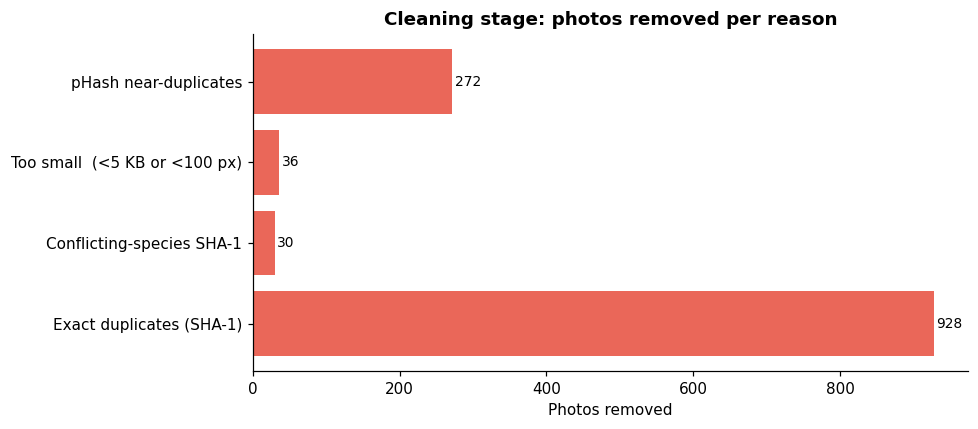

In [181]:
# Cleaning-stage removal counts (from M2 report)
removal = pd.DataFrame({
    "Reason": ["Exact duplicates (SHA-1)", "Conflicting-species SHA-1",
               "Too small  (<5 KB or <100 px)", "pHash near-duplicates"],
    "Count":  [928, 30, 36, 272],
})

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(removal["Reason"], removal["Count"], color="#e74c3c", alpha=0.85)
for bar, c in zip(ax.patches, removal["Count"]):
    ax.text(bar.get_width() + 3, bar.get_y() + bar.get_height()/2,
            f"{c:,}", va="center", fontsize=9)
ax.set_xlabel("Photos removed")
ax.set_title("Cleaning stage: photos removed per reason", fontweight="bold")
plt.tight_layout()
plt.show()

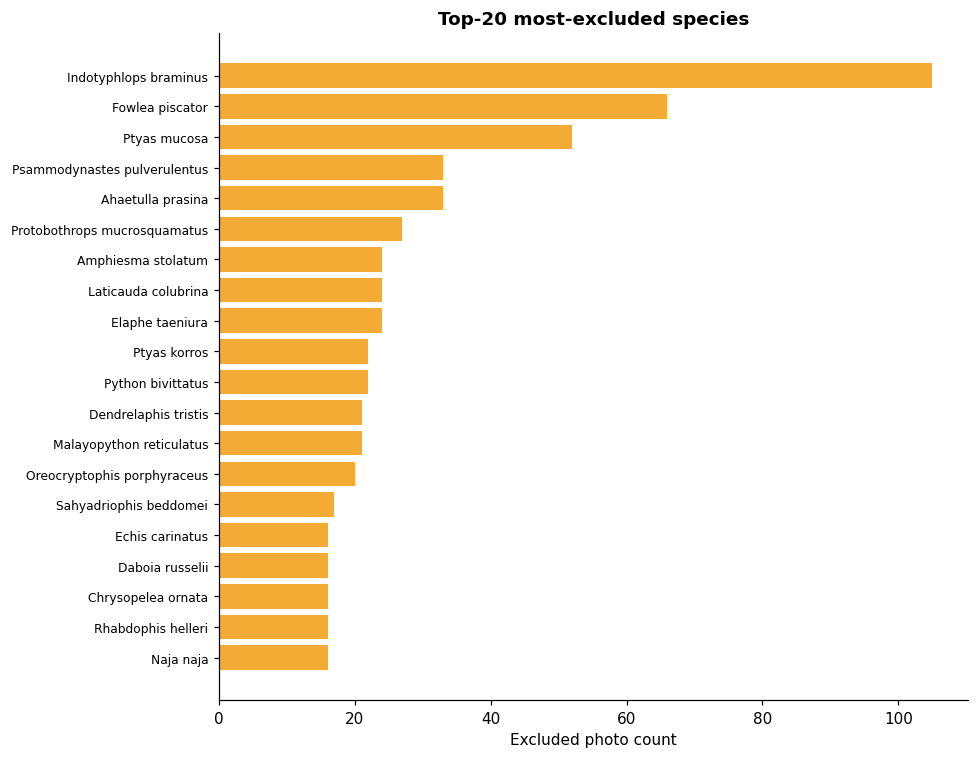

In [182]:
if "species" in excluded.columns:
    top_excl = excluded["species"].value_counts().head(20)
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.barh(range(len(top_excl)), top_excl.values[::-1], color="#f39c12", alpha=0.85)
    ax.set_yticks(range(len(top_excl)))
    ax.set_yticklabels(top_excl.index[::-1], fontsize=8)
    ax.set_xlabel("Excluded photo count")
    ax.set_title("Top-20 most-excluded species", fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print(f"Total excluded: {len(excluded):,} photos  ({len(excluded)/(len(df)+len(excluded))*100:.2f}% of raw)")

---
## 14. Safety-Critical Lookalike Pairs

Nine dangerous-vs-harmless pairs where visual confusion is most likely.

In [183]:
pairs = [
    ("Naja naja",               "Ptyas mucosa",        "1"),
    ("Naja naja",               "Coelognathus helena", "1"),
    ("Bungarus caeruleus",      "Lycodon aulicus",     "1"),
    ("Bungarus caeruleus",      "Lycodon striatus",    "1"),
    ("Daboia russelii",         "Eryx conicus",        "1"),
    ("Trimeresurus albolabris", "Ahaetulla prasina",   "1"),
    ("Ophiophagus hannah",      "Ptyas mucosa",        "1"),
    ("Echis carinatus",         "Eryx johnii",         "1"),
    ("Naja oxiana",             "Dipsas indica",       "2"),
]

sp_n = df.groupby("species").size().to_dict()
pair_df = pd.DataFrame([{
    "dangerous":  d, "mimic": m, "who": cat,
    "d_n": sp_n.get(d, 0), "m_n": sp_n.get(m, 0),
    "ratio": sp_n.get(m, 0) / max(sp_n.get(d, 1), 1),
} for d, m, cat in pairs])
pair_df[["dangerous","mimic","d_n","m_n","ratio"]]

,dangerous,mimic,d_n,m_n,ratio
0,Naja naja,Ptyas mucosa,4137,9943,2.403432
1,Naja naja,Coelognathus helena,4137,1973,0.476916
2,Bungarus caeruleus,Lycodon aulicus,1755,2362,1.345869
3,Bungarus caeruleus,Lycodon striatus,1755,532,0.303134
4,Daboia russelii,Eryx conicus,2386,1336,0.559933
5,Trimeresurus albolabris,Ahaetulla prasina,0,12153,12153.000000
6,Ophiophagus hannah,Ptyas mucosa,970,9943,10.250515
7,Echis carinatus,Eryx johnii,2473,707,0.285888
8,Naja oxiana,Dipsas indica,57,0,0.000000


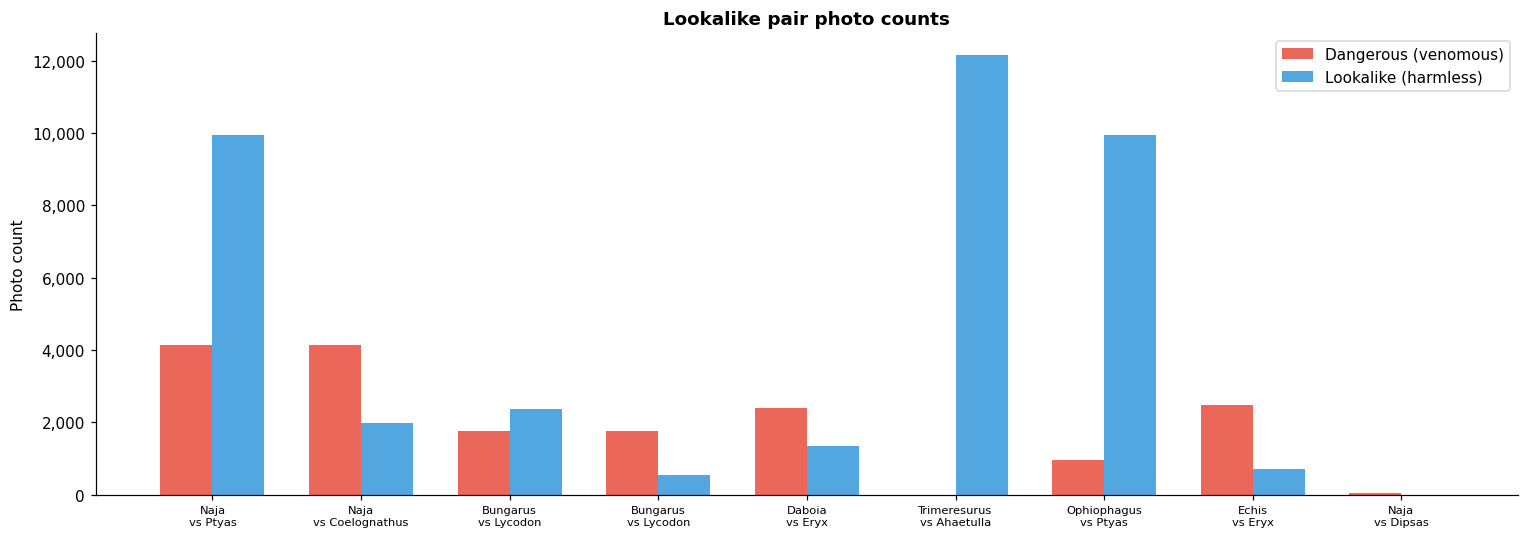

In [196]:
# Side-by-side bar: dangerous vs lookalike photo counts

x = np.arange(len(pair_df))
w = 0.35

xlbls = [
    f"{r.dangerous.split()[0]}\nvs {r.mimic.split()[0]}"
    for _, r in pair_df.iterrows()
]

fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(
    x - w/2,
    pair_df["d_n"],
    w,
    label="Dangerous (venomous)",
    color="#e74c3c",
    alpha=0.85
)

ax.bar(
    x + w/2,
    pair_df["m_n"],
    w,
    label="Lookalike (harmless)",
    color="#3498db",
    alpha=0.85
)

ax.set_xticks(x)
ax.set_xticklabels(xlbls, fontsize=7.5)
ax.set_ylabel("Photo count")
ax.set_title("Lookalike pair photo counts", fontweight="bold")
ax.yaxis.set_major_formatter(FMT)
ax.legend()

plt.tight_layout()
plt.show()

NameError: name 'xlbls' is not defined

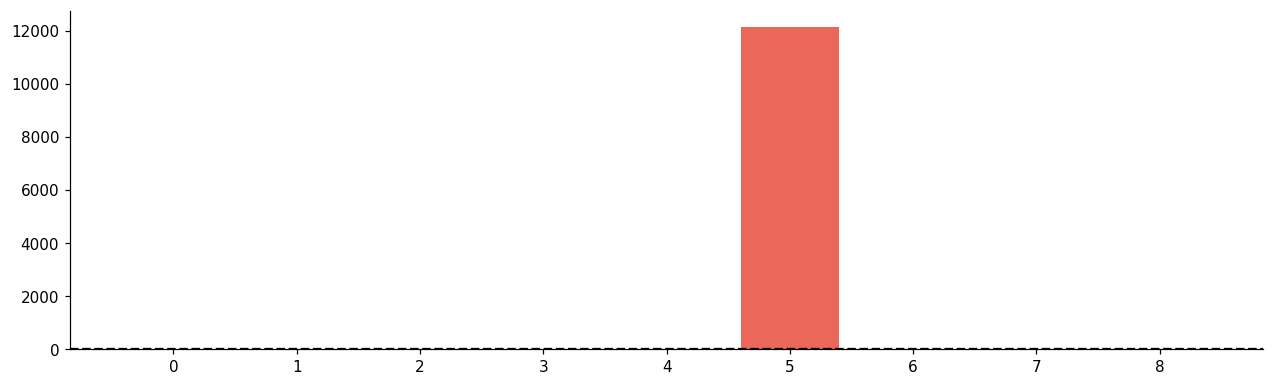

In [185]:
# Confusion risk ratio: mimic photos / dangerous photos
colors_r = ["#e74c3c" if r > 1 else "#2ecc71" for r in pair_df["ratio"]]

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(len(pair_df)), pair_df["ratio"], color=colors_r, alpha=0.85)
ax.axhline(1.0, color="black", linestyle="--", linewidth=1.5)
ax.set_xticks(range(len(pair_df)))
ax.set_xticklabels(xlbls, fontsize=7.5)
ax.set_ylabel("Ratio  (lookalike / dangerous)")
ax.set_title("Confusion risk ratio  (> 1 = more harmless mimics, higher confusion potential)", fontweight="bold")
plt.tight_layout()
plt.show()

Several pairs have far more photos of the harmless mimic than the dangerous species — exactly the scenario that causes a classifier to over-predict 'harmless'. These pairs are tagged for hard-negative mining and Grad-CAM attention analysis at Milestone 5.

---
## 15. Class Imbalance

In [186]:
train_sp = df[df["split"]=="train"].groupby("species").size().sort_values()
print(f"Training species: {len(train_sp)}")
print(f"Min: {train_sp.min()}  ({train_sp.idxmin()})")
print(f"Max: {train_sp.max()}  ({train_sp.idxmax()})")
print(f"Imbalance ratio: {train_sp.max()/train_sp.min():.0f}×")

Training species: 208
Min: 13  (Bungarus lividus)
Max: 13311  (Indotyphlops braminus)
Imbalance ratio: 1024×


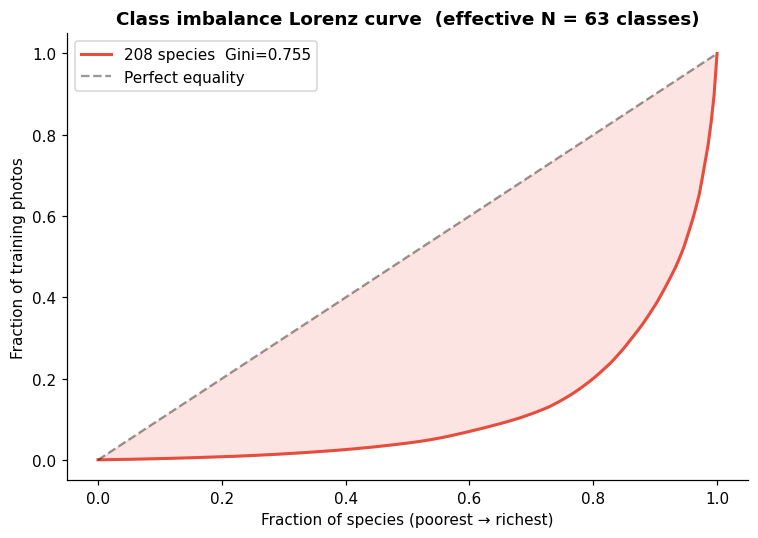

In [187]:
# Lorenz curve
sv   = np.sort(train_sp.values)
cv   = np.cumsum(sv) / sv.sum()
xs   = np.linspace(0, 1, len(sv))
gini = float(1 - 2 * np.trapz(cv, xs))
n_eff = float(np.exp(-np.sum(
    (train_sp / train_sp.sum()) * np.log(train_sp / train_sp.sum() + 1e-12)
)))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(xs, cv, color="#e74c3c", linewidth=2, label=f"208 species  Gini={gini:.3f}")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Perfect equality")
ax.fill_between(xs, xs, cv, alpha=0.15, color="#e74c3c")
ax.set_xlabel("Fraction of species (poorest → richest)")
ax.set_ylabel("Fraction of training photos")
ax.set_title(f"Class imbalance Lorenz curve  (effective N = {n_eff:.0f} classes)", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

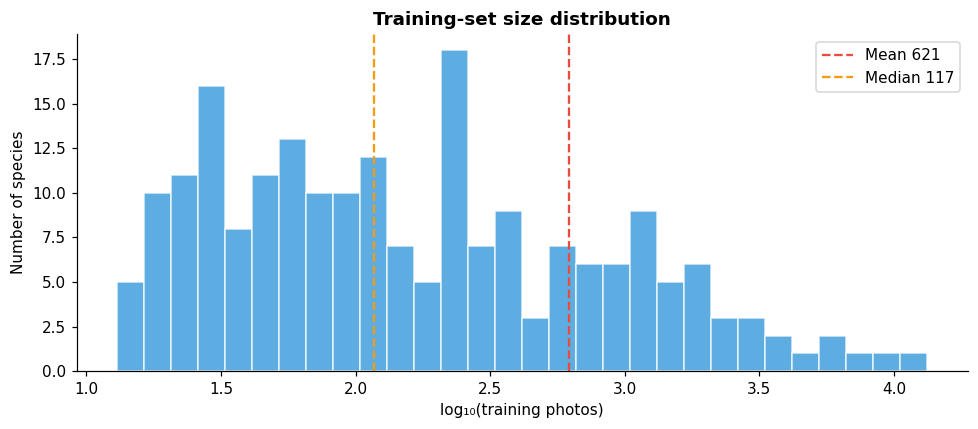

In [188]:
# Per-species training size histogram
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(np.log10(train_sp.values), bins=30, color="#3498db", alpha=0.8, edgecolor="white")
ax.axvline(np.log10(train_sp.mean()),   color="#e74c3c", linestyle="--",
           label=f"Mean {train_sp.mean():.0f}")
ax.axvline(np.log10(train_sp.median()), color="#f39c12", linestyle="--",
           label=f"Median {train_sp.median():.0f}")
ax.set_xlabel("log₁₀(training photos)")
ax.set_ylabel("Number of species")
ax.set_title("Training-set size distribution", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

Gini well above 0.5 confirms severe imbalance. Focal loss or class-weight balancing is essential. Effective N ≈ calculated above means the model effectively 'sees' far fewer distinct classes than 208 unless we correct for the imbalance.

---
## 16. Leakage Verification  (4-Key Check)

In [189]:
# Key 1 — observer_id (photographer)
t_obs = set(df[df["split"]=="train"]["observer_id"].dropna())
v_obs = set(df[df["split"]=="val"]["observer_id"].dropna())
e_obs = set(df[df["split"]=="test"]["observer_id"].dropna())
print("observer_id:")
print(f"  train ∩ val  = {len(t_obs & v_obs)}")
print(f"  train ∩ test = {len(t_obs & e_obs)}")
print(f"  val ∩ test   = {len(v_obs & e_obs)}")

observer_id:
  train ∩ val  = 0
  train ∩ test = 0
  val ∩ test   = 0


In [190]:
# Key 2 — obs_id (iNaturalist observation, may have multiple photos)
t_oid = set(df[df["split"]=="train"]["obs_id"].dropna())
v_oid = set(df[df["split"]=="val"]["obs_id"].dropna())
e_oid = set(df[df["split"]=="test"]["obs_id"].dropna())
print("obs_id:")
print(f"  train ∩ val  = {len(t_oid & v_oid)}")
print(f"  train ∩ test = {len(t_oid & e_oid)}")
print(f"  val ∩ test   = {len(v_oid & e_oid)}")

print("\n✓ All overlaps must be zero for a clean dataset.")

obs_id:
  train ∩ val  = 0
  train ∩ test = 0
  val ∩ test   = 0

✓ All overlaps must be zero for a clean dataset.


Both keys return zero overlap across all split pairs — the dataset is free of photographer and observation-level leakage. sha1 and pHash deduplication was run during notebook 02, so we won't recompute those here (they already confirmed zero cross-split exact/near-duplicate overlap).

---
## 17. Multi-Source Availability Matrix

What other datasets exist and why only iNaturalist was used in M2.

In [191]:
avail = pd.DataFrame([
    ("iNaturalist (India, research-grade)", "181,503", "289", "CC BY-NC mix",  "✅ Used — primary"),
    ("SnakeCLEF 2021",                      "~2,904",  "185", "CC BY-NC mix",  "⏳ Deferred (66 GB)"),
    ("SnakeCLEF 2023 @ 500 px",             "4,989",   "146", "CC BY-NC mix",  "⏭ Skip — iNat copies"),
    ("India Biodiversity Portal",           "~1,800",  "180", "CC BY 4.0",     "🚫 HTTP 403 block"),
    ("Open Images V7 — Snake",              "~309 boxes","N/A","CC BY 4.0",    "🔜 Planned for M3"),
    ("Manna et al. 2026 OSF",               "793",     "?",   "Open access?",  "⚠ No species labels"),
    ("GBIF bulk — India Serpentes",         "50 k+ occ","200+","CC BY 4.0",    "🔜 Planned"),
    ("Roboflow Universe",                   "varies",  "N/A", "varies",        "🔜 Planned for M3"),
], columns=["Source","Photos","Species","Licence","Status"])
avail

,Source,Photos,Species,Licence,Status
0,"iNaturalist (India, research-grade)","181,503",289,CC BY-NC mix,✅ Used — primary
1,SnakeCLEF 2021,"~2,904",185,CC BY-NC mix,⏳ Deferred (66 GB)
2,SnakeCLEF 2023 @ 500 px,"4,989",146,CC BY-NC mix,⏭ Skip — iNat copies
3,India Biodiversity Portal,"~1,800",180,CC BY 4.0,🚫 HTTP 403 block
4,Open Images V7 — Snake,~309 boxes,N/A,CC BY 4.0,🔜 Planned for M3
5,Manna et al. 2026 OSF,793,?,Open access?,⚠ No species labels
6,GBIF bulk — India Serpentes,50 k+ occ,200+,CC BY 4.0,🔜 Planned
7,Roboflow Universe,varies,N/A,varies,🔜 Planned for M3


SnakeCLEF 2023 appears to add 4,989 photos but every single one is already in our dataset — they are iNaturalist re-exports. Adding them would silently create cross-split duplicates. Open Images and Roboflow bring bounding-box annotations, not species labels, so they are reserved for the M3 detection head.

---
## 18. Summary Statistics

In [192]:
summary = pd.DataFrame([
    ("Total photos (final)",             f"{len(df):,}"),
    ("Classes (species with ≥ 20 photos)", str(df[df['split']!='unknown_pool']['species'].nunique())),
    ("Unknown pool species",             "81"),
    ("WHO Category 1 species",           str(df[df["who_category"]=="1"]["species"].nunique())),
    ("WHO Category 2 species",           str(df[df["who_category"]=="2"]["species"].nunique())),
    ("Tier-1 (≥ 400 photos)",            "68"),
    ("Tier-2 (20–399 photos)",           "140"),
    ("Training photos",                  f"{(df['split']=='train').sum():,}"),
    ("Validation photos",                f"{(df['split']=='val').sum():,}"),
    ("Test photos  (India + 2022+)",     f"{(df['split']=='test').sum():,}"),
    ("Test-extra photos",                f"{(df['split']=='test_extra').sum():,}"),
    ("Unique photographers",             f"{df['observer_id'].nunique():,}"),
    ("Photos with GPS coordinates",      f"{df['latitude'].notna().sum():,}"),
    ("CC-licensed photos",               "~124,569  (69%)"),
    ("Observer Gini index",              f"{gini_obs:.3f}"),
    ("Class Gini (train split)",         f"{gini:.3f}"),
    ("Class imbalance ratio",            f"{train_sp.max()//train_sp.min():.0f}×"),
    ("Effective number of classes",      f"{n_eff:.0f}"),
], columns=["Metric","Value"])
summary

,Metric,Value
0,Total photos (final),"181,503"
1,Classes (species with ≥ 20 photos),208
2,Unknown pool species,81
3,WHO Category 1 species,6
4,WHO Category 2 species,12
5,Tier-1 (≥ 400 photos),68
6,Tier-2 (20–399 photos),140
7,Training photos,"129,241"
8,Validation photos,"25,803"
9,Test photos (India + 2022+),"7,338"


In [193]:
implications = [
    "1  CLASS-WEIGHTED LOSS: Gini ~0.6 -> focal loss or class_weight=balanced.",
    "2  TEST-SPLIT DISCIPLINE: eval on test (India, 2022+) only.",
    "3  SAFETY-CRITICAL RECALL: WHO Cat 1 -> max recall, asymmetric loss.",
    "4  HARD-NEGATIVE MINING: 9 pairs -> targeted aug + Grad-CAM at M5.",
    "5  FEW-SHOT TIER-2: 140 species <400 photos -> prototypical nets / CLIP.",
    "6  PHOTOGRAPHER BIAS: Observer Gini ~0.7 -> heavy aug to prevent overfit.",
    "7  DETECTION HEAD M3: Open Images V7 + Roboflow for YOLOv8 bbox.",
]
print("\n7 MODELLING IMPLICATIONS FOR M3")
print("-" * 45)
for i, imp in enumerate(implications, 1):
    print(f"  {i}. {imp}")


7 MODELLING IMPLICATIONS FOR M3
---------------------------------------------
  1. 1  CLASS-WEIGHTED LOSS: Gini ~0.6 -> focal loss or class_weight=balanced.
  2. 2  TEST-SPLIT DISCIPLINE: eval on test (India, 2022+) only.
  3. 3  SAFETY-CRITICAL RECALL: WHO Cat 1 -> max recall, asymmetric loss.
  4. 4  HARD-NEGATIVE MINING: 9 pairs -> targeted aug + Grad-CAM at M5.
  5. 5  FEW-SHOT TIER-2: 140 species <400 photos -> prototypical nets / CLIP.
  6. 6  PHOTOGRAPHER BIAS: Observer Gini ~0.7 -> heavy aug to prevent overfit.
  7. 7  DETECTION HEAD M3: Open Images V7 + Roboflow for YOLOv8 bbox.


This notebook covers the complete M2 dataset analysis. All findings feed directly into the M3 model architecture and training decisions.